# ERCOT Regional Load Forecasting — Workflow

This notebook develops and evaluates hourly load-forecasting models for eight ERCOT weather zones, then aggregates their predictions to the ERCOT system level.

**Workflow:** prepare and validate the zone-level load/weather dataset; construct lag-24 and lag-168 baselines; create chronological training/validation/test sets; evaluate Ridge and histogram gradient boosting (HGB); use 2023 and 2024 validation to select a model; retrain on 2019–2024 and evaluate 2025; analyze high-load and annual-peak errors; export hourly predictions for the subsequent peak-uncertainty and capacity-planning notebooks.

**Evaluation scope:** The 2025 evaluation is **pseudo-out-of-sample**: model parameters are selected using earlier years, but lagged *observed* loads and contemporaneous *realized* weather are used as features. This is not an operational, year-ahead forecast made without knowledge of 2025 conditions. Quantile calibration and peak-bias adjustment are addressed in later notebooks.

**Reproduction:** Run the cells from top to bottom from the repository root or the `notebooks/` directory. This notebook expects the locally prepared `data/modeling/regional_load_weather_features_2019_2025.parquet` file. The original saved outputs are provided for inspection but have **not** been reproduced in a fresh environment as part of this GitHub cleanup.


### Forecasting objectives

1. Establish lag-24 and lag-168 persistence baselines.
2. Split time-ordered data into training, validation, and test periods.
3. Fit interpretable calendar-and-weather Ridge regression models.
4. Examine nonlinear gradient-boosted tree models.
5. Compare predictions at regional and ERCOT system levels.
6. Diagnose average-load and annual-peak forecasting errors.


## 1. Imports and repository-relative paths

Resolve paths relative to the project folder, not a specific person's computer. Output messages intentionally display repository-relative locations; underlying file operations still use absolute `Path` objects resolved from the project root.


In [ ]:
# Import numerical analysis, data handling, plotting, and path utilities.
from pathlib import Path


import numpy as np


import pandas as pd


import matplotlib.pyplot as plt


import seaborn as sns


pd.set_option(
    
    "display.max_columns",
    
    100,
)


pd.set_option(
    
    "display.float_format",
    
    lambda value: f"{value:,.3f}",
)


sns.set_theme(
    
    style="whitegrid",
    
    context="notebook",
)


In [ ]:
# Locate the project root and configure local input/output directories.
current_directory = Path.cwd().resolve()


if (current_directory / "data").exists():
    
    project_root = current_directory
else:
    
    project_root = current_directory.parent


def display_repo_path(path):
    """Return a repository-relative path for logs without disclosing the host directory."""
    try:
        return str(Path(path).resolve().relative_to(project_root)) or "."
    except ValueError:
        return "[path outside repository]"

forecasting_data_path = (
    
    project_root
    
    / "data"
    
    / "modeling"
    
    / "regional_load_weather_features_2019_2025.parquet"
)


if not forecasting_data_path.exists():
    
    raise FileNotFoundError(
        "Forecasting dataset not found: "
        f"{display_repo_path(forecasting_data_path)}"
    )


forecasting_tables_dir = (
    
    project_root
    
    / "report"
    
    / "tables"
    
    / "forecasting"
)


forecasting_figures_dir = (
    
    project_root
    
    / "report"
    
    / "figures"
    
    / "forecasting"
)


forecasting_tables_dir.mkdir(
    
    parents=True,
    
    exist_ok=True,
)


forecasting_figures_dir.mkdir(
    
    parents=True,
    
    exist_ok=True,
)


print("Project root:", display_repo_path(project_root))


print("Forecasting data:", display_repo_path(forecasting_data_path))


print("Forecasting tables:", display_repo_path(forecasting_tables_dir))


print("Forecasting figures:", display_repo_path(forecasting_figures_dir))


Project root: .
Forecasting data: data/modeling/regional_load_weather_features_2019_2025.parquet
Forecasting tables: report/tables/forecasting
Forecasting figures: report/figures/forecasting


### Validate the forecasting dataset


## 2. Load and validate the modeling dataset

Load the zone-hour weather and demand feature file, verify required fields, and prepare timestamps and data types.


In [ ]:
# Read and validate regional hourly load and weather features.
forecast_data = pd.read_parquet(
    
    forecasting_data_path,
    
    engine="pyarrow",
)


required_forecasting_columns = {
    # UTC Hour Ending。
    "HourEnding_utc",
    
    "interval_start_local",
    # Weather Zone。
    "zone",
    
    "load_mw",
    
    "zone_total_mismatch_flag",
    
    "local_year",
    
    "month",
    
    "day_of_week",
    
    "hour",
    
    "is_weekend",
    # CDD。
    "cooling_degree_c",
    # HDD。
    "heating_degree_c",
}


missing_forecasting_columns = (
    
    required_forecasting_columns
    - set(forecast_data.columns)
)


if missing_forecasting_columns:
    
    raise ValueError(
        "Missing forecasting columns / "
        "Missing required forecasting columns: "
        f"{sorted(missing_forecasting_columns)}"
    )


forecast_data["HourEnding_utc"] = pd.to_datetime(
    
    forecast_data["HourEnding_utc"],
    
    utc=True,
    
    errors="raise",
)


forecast_data = forecast_data.sort_values(
    
    [
        "zone",
        "HourEnding_utc",
    ]

).reset_index(
    
    drop=True
)


forecast_startup_check = pd.Series({
    
    "row_count": len(forecast_data),
    
    "row_count_matches": (
        len(forecast_data) == 490_944
    ),
    
    "zone_count": forecast_data[
        "zone"
    ].nunique(),
    
    "duplicate_zone_time_keys": int(
        forecast_data.duplicated(
            subset=[
                "zone",
                "HourEnding_utc",
            ]
        ).sum()
    ),
    
    "missing_target_values": int(
        forecast_data[
            "load_mw"
        ].isna().sum()
    ),
    
    "missing_degree_values": int(
        forecast_data[
            [
                "cooling_degree_c",
                "heating_degree_c",
            ]
        ].isna().sum().sum()
    ),
    
    "flagged_long_rows": int(
        forecast_data[
            "zone_total_mismatch_flag"
        ].sum()
    ),

}, name="value")


print(
    forecast_startup_check.to_string()
)


row_count                   490944
row_count_matches             True
zone_count                       8
duplicate_zone_time_keys         0
missing_target_values            0
missing_degree_values            0
flagged_long_rows              384


### Create lagged-load features


## 3. Lagged-load predictors

Construct zone-specific 24-hour and 168-hour persistence features, along with quality information about their source observations.


In [ ]:
# Construct lag-24 and lag-168 predictors within each weather zone.
zone_groups = forecast_data.groupby(
    
    "zone",
    
    sort=False,
)


forecast_data["lag_24"] = (
    
    zone_groups[
        "load_mw"
    ]
    
    .shift(24)
)


forecast_data["lag_168"] = (
    
    zone_groups[
        "load_mw"
    ]
    
    .shift(168)
)


forecast_data["lag_24_source_flag"] = (
    
    zone_groups[
        "zone_total_mismatch_flag"
    ]
    
    .shift(24)
)


forecast_data["lag_168_source_flag"] = (
    
    zone_groups[
        "zone_total_mismatch_flag"
    ]
    
    .shift(168)
)


lag_feature_check = pd.Series({
    
    "missing_lag_24": int(
        forecast_data[
            "lag_24"
        ].isna().sum()
    ),
    
    "missing_lag_168": int(
        forecast_data[
            "lag_168"
        ].isna().sum()
    ),
    
    "flagged_lag_24_sources": int(
        forecast_data[
            "lag_24_source_flag"
        ].fillna(False).sum()
    ),
    
    "flagged_lag_168_sources": int(
        forecast_data[
            "lag_168_source_flag"
        ].fillna(False).sum()
    ),

}, name="value")


print(
    lag_feature_check.to_string()
)


missing_lag_24              192
missing_lag_168            1344
flagged_lag_24_sources      384
flagged_lag_168_sources     384


### Define chronological training, validation, and test sets


## 4. Chronological splits

Use 2019–2023 as the initial training data, 2024 for model tuning, and 2025 as a held-out evaluation year. A separate 2023 rolling validation later checks year-to-year stability.


In [ ]:
# Create the chronological initial training, validation, and test periods.
training_years = [
    
    2019,
    
    2020,
    
    2021,
    
    2022,
    
    2023,
]


validation_year = 2024


test_year = 2025


train_data = forecast_data.loc[
    
    forecast_data[
        "local_year"
    ].isin(
        training_years
    )
].copy()


validation_data = forecast_data.loc[
    
    forecast_data[
        "local_year"
    ] == validation_year
].copy()


test_data = forecast_data.loc[
    
    forecast_data[
        "local_year"
    ] == test_year
].copy()


time_split_summary = pd.DataFrame({
    
    "dataset": [
        "Training",
        "Validation",
        "Test",
    ],
    
    "years": [
        "2019–2023",
        "2024",
        "2025",
    ],
    
    "row_count": [
        len(train_data),
        len(validation_data),
        len(test_data),
    ],
    
    "utc_start": [
        train_data[
            "HourEnding_utc"
        ].min(),
        validation_data[
            "HourEnding_utc"
        ].min(),
        test_data[
            "HourEnding_utc"
        ].min(),
    ],
    
    "utc_end": [
        train_data[
            "HourEnding_utc"
        ].max(),
        validation_data[
            "HourEnding_utc"
        ].max(),
        test_data[
            "HourEnding_utc"
        ].max(),
    ],
})


display(time_split_summary)


,dataset,years,row_count,utc_start,utc_end
0,Training,2019–2023,350592,2019-01-01 07:00:00+00:00,2024-01-01 06:00:00+00:00
1,Validation,2024,70272,2024-01-01 07:00:00+00:00,2025-01-01 06:00:00+00:00
2,Test,2025,70080,2025-01-01 07:00:00+00:00,2026-01-01 06:00:00+00:00


### Evaluate lag baselines on the 2024 validation data


## 5. Validation metrics and persistence baselines

Report **MAE**, **RMSE**, **WAPE** (sum of absolute errors divided by sum of absolute actual loads), and **bias** (mean prediction minus actual load). All load magnitudes are in MW unless noted.


In [ ]:
# Define MAE, RMSE, WAPE, and signed bias metrics.
def calculate_forecast_metrics(
    
    actual_values,
    
    predicted_values,
):
    """Calculate standard load-forecasting metrics.

    """

    
    actual_array = np.asarray(
        
        actual_values,
        
        dtype=float,
    )

    
    predicted_array = np.asarray(
        
        predicted_values,
        
        dtype=float,
    )

    
    forecast_errors = (
        predicted_array - actual_array
    )

    
    mae_mw = np.mean(
        
        np.abs(forecast_errors)
    )

    
    rmse_mw = np.sqrt(
        
        np.mean(
            forecast_errors ** 2
        )
    )

    
    wape_pct = (
        
        np.sum(
            np.abs(forecast_errors)
        )
        
        / np.sum(
            np.abs(actual_array)
        )
        
        * 100
    )

    
    bias_mw = np.mean(
        
        forecast_errors
    )

    
    return pd.Series({
        
        "observation_count": len(
            actual_array
        ),
        
        "mae_mw": mae_mw,
        
        "rmse_mw": rmse_mw,
        
        "wape_pct": wape_pct,
        
        "bias_mw": bias_mw,
    })


### Comparable validation samples

To compare lag-based baselines fairly, retain only observations with a valid target load, an available lag-24 load from an unflagged source hour, and an available lag-168 load from an unflagged source hour. All model comparisons below use aligned samples at the relevant comparison stage.


In [ ]:
# Select a shared set of quality-screened 2024 validation rows.
validation_common_mask = (
    
    ~validation_data[
        "zone_total_mismatch_flag"
    ]
    
    & validation_data[
        "lag_24"
    ].notna()
    
    & validation_data[
        "lag_168"
    ].notna()
    
    & ~validation_data[
        "lag_24_source_flag"
    ].fillna(False)
    
    & ~validation_data[
        "lag_168_source_flag"
    ].fillna(False)
)


baseline_validation_data = validation_data.loc[
    
    validation_common_mask
].copy()


baseline_validation_data[
    "prediction_lag_24"
] = baseline_validation_data[
    "lag_24"
]


baseline_validation_data[
    "prediction_lag_168"
] = baseline_validation_data[
    "lag_168"
]


baseline_validation_check = pd.Series({
    
    "original_validation_rows": len(
        validation_data
    ),
    
    "eligible_validation_rows": len(
        baseline_validation_data
    ),
    
    "excluded_validation_rows": (
        len(validation_data)
        - len(baseline_validation_data)
    ),
    
    "zone_count": baseline_validation_data[
        "zone"
    ].nunique(),
    
    "missing_lag_24_predictions": int(
        baseline_validation_data[
            "prediction_lag_24"
        ].isna().sum()
    ),
    
    "missing_lag_168_predictions": int(
        baseline_validation_data[
            "prediction_lag_168"
        ].isna().sum()
    ),

}, name="value")


print(
    baseline_validation_check.to_string()
)


original_validation_rows       70272
eligible_validation_rows       70272
excluded_validation_rows           0
zone_count                         8
missing_lag_24_predictions         0
missing_lag_168_predictions        0


In [ ]:
# Compare regional persistence baseline accuracy.
baseline_models = {
    
    "Lag 24": "prediction_lag_24",
    
    "Lag 168": "prediction_lag_168",
}


regional_baseline_records = []


for model_name, prediction_column in (
    baseline_models.items()
):
    
    overall_metrics = calculate_forecast_metrics(
        
        baseline_validation_data[
            "load_mw"
        ],
        
        baseline_validation_data[
            prediction_column
        ],
    )

    
    regional_baseline_records.append({
        
        "model": model_name,
        
        "zone": "ALL_REGIONAL_ROWS",
        
        **overall_metrics.to_dict(),
    })

    
    for current_zone, current_zone_data in (
        baseline_validation_data.groupby(
            
            "zone"
        )
    ):
        
        zone_metrics = calculate_forecast_metrics(
            
            current_zone_data[
                "load_mw"
            ],
            
            current_zone_data[
                prediction_column
            ],
        )

        
        regional_baseline_records.append({
            
            "model": model_name,
            
            "zone": current_zone,
            
            **zone_metrics.to_dict(),
        })


regional_baseline_metrics = pd.DataFrame(
    
    regional_baseline_records
)


regional_baseline_metrics = (
    regional_baseline_metrics.sort_values(
        
        [
            "zone",
            "model",
        ]
    )
    
    .reset_index(
        
        drop=True
    )
)


print(
    regional_baseline_metrics.loc[
        regional_baseline_metrics[
            "zone"
        ] == "ALL_REGIONAL_ROWS",
        [
            "model",
            "observation_count",
            "mae_mw",
            "rmse_mw",
            "wape_pct",
            "bias_mw",
        ],
    ].round(3).to_string(
        index=False
    )
)


display(
    regional_baseline_metrics.loc[
        regional_baseline_metrics[
            "zone"
        ] != "ALL_REGIONAL_ROWS",
        [
            "model",
            "zone",
            "mae_mw",
            "rmse_mw",
            "wape_pct",
            "bias_mw",
        ],
    ]
)


  model  observation_count  mae_mw   rmse_mw  wape_pct  bias_mw
Lag 168         70,272.000 641.810 1,272.726     9.773    4.478
 Lag 24         70,272.000 373.034   746.710     5.680   -0.312


,model,zone,mae_mw,rmse_mw,wape_pct,bias_mw
2,Lag 168,COAST,"1,332.729","1,985.366",9.510,6.317
3,Lag 24,COAST,768.000,"1,166.778",5.480,0.360
4,Lag 168,EAST,212.238,299.530,12.255,6.826
5,Lag 24,EAST,129.243,189.126,7.463,0.313
6,Lag 168,FWEST,187.387,246.194,2.849,-16.601
7,Lag 24,FWEST,149.850,201.573,2.278,-2.585
8,Lag 168,NCENT,"1,864.842","2,585.642",12.654,31.785
9,Lag 24,NCENT,"1,038.611","1,507.944",7.048,-0.185
10,Lag 168,NORTH,133.378,178.894,9.002,-1.411
11,Lag 24,NORTH,85.760,116.442,5.788,-0.470


In [ ]:
# Aggregate baseline predictions to the ERCOT system level.
system_baseline_predictions = (
    
    baseline_validation_data
    
    .groupby(
        
        "HourEnding_utc",
        
        as_index=False,
    )
    
    .agg(
        
        actual_system_load_mw=(
            "load_mw",
            "sum",
        ),
        
        prediction_lag_24_mw=(
            "prediction_lag_24",
            "sum",
        ),
        
        prediction_lag_168_mw=(
            "prediction_lag_168",
            "sum",
        ),
    )
)


system_baseline_records = []


system_prediction_columns = {
    
    "Lag 24": "prediction_lag_24_mw",
    
    "Lag 168": "prediction_lag_168_mw",
}


for model_name, prediction_column in (
    system_prediction_columns.items()
):
    
    system_metrics = calculate_forecast_metrics(
        
        system_baseline_predictions[
            "actual_system_load_mw"
        ],
        
        system_baseline_predictions[
            prediction_column
        ],
    )

    
    system_baseline_records.append({
        
        "model": model_name,
        
        **system_metrics.to_dict(),
    })


system_baseline_metrics = pd.DataFrame(
    
    system_baseline_records
)


print(
    system_baseline_metrics.round(
        3
    ).to_string(
        index=False
    )
)


  model  observation_count    mae_mw   rmse_mw  wape_pct  bias_mw
 Lag 24          8,784.000 2,336.789 3,384.824     4.448   -2.498
Lag 168          8,784.000 4,478.686 6,274.319     8.525   35.824


In [ ]:
# Export 2024 persistence baseline metrics.
regional_baseline_metrics_path = (
    
    forecasting_tables_dir
    
    / "validation_2024_regional_baseline_metrics.csv"
)


system_baseline_metrics_path = (
    
    forecasting_tables_dir
    
    / "validation_2024_system_baseline_metrics.csv"
)


regional_baseline_metrics.to_csv(
    
    regional_baseline_metrics_path,
    
    index=False,
)


system_baseline_metrics.to_csv(
    
    system_baseline_metrics_path,
    
    index=False,
)


print(
    "Regional baseline metrics saved to:",
    display_repo_path(regional_baseline_metrics_path),
)

print(
    "System baseline metrics saved to:",
    display_repo_path(system_baseline_metrics_path),
)


Regional baseline metrics saved to: report/tables/forecasting/validation_2024_regional_baseline_metrics.csv
System baseline metrics saved to: report/tables/forecasting/validation_2024_system_baseline_metrics.csv


> **Baseline interpretation:** Lag-24 uses the same zone's observed load from 24 hours earlier; lag-168 uses the observed load from 168 hours earlier. These are persistence benchmarks, not trained predictive models.


### Move from baselines to interpretable modeling

Lag-24 is the primary baseline and lag-168 is a supplementary comparison. The next model combines lagged loads, calendar effects, weather-related variables, and a year trend with a Ridge regression pipeline.


> **Dependency:** Install the project's dependencies from `requirements.txt` before running this notebook. Package installation is intentionally not performed inside the notebook.


## 6. Interpretable weather-and-calendar Ridge models

Fit one regularized linear regression pipeline per weather zone. Candidate regularization strengths are evaluated using the 2024 validation data, with metrics assessed at regional and system levels.


In [ ]:
# Define preprocessing and estimation tools for regularized regression.
# 12.1

import numpy as np


import pandas as pd


from sklearn.compose import ColumnTransformer


from sklearn.preprocessing import StandardScaler, OneHotEncoder


from sklearn.linear_model import Ridge


from sklearn.pipeline import Pipeline

ridge_numeric_features = [
    
    "lag_24",
    
    "lag_168",
    
    "cooling_degree_c",
    
    "heating_degree_c",
    
    "local_year",
]

ridge_categorical_features = [
    
    "hour",
    
    "day_of_week",
    
    "month",
]

ridge_feature_columns = (
    ridge_numeric_features
    + ridge_categorical_features
)

missing_ridge_columns = [
    
    column
    
    for column in ridge_feature_columns
    
    if column not in forecast_data.columns
]

if missing_ridge_columns:
    
    raise KeyError(
        f"Missing required Ridge model columns: {missing_ridge_columns}"
    )

print("Ridge numeric features:")
print(ridge_numeric_features)


print("\nRidge categorical features:")
print(ridge_categorical_features)


Ridge numeric features:
['lag_24', 'lag_168', 'cooling_degree_c', 'heating_degree_c', 'local_year']

Ridge categorical features:
['hour', 'day_of_week', 'month']


In [ ]:
# Prepare quality-screened Ridge training and validation samples.
current_load_is_valid = ~forecast_data[
    "zone_total_mismatch_flag"
].fillna(False).astype(bool)

lag_24_source_is_valid = ~forecast_data[
    "lag_24_source_flag"
].fillna(True).astype(bool)

lag_168_source_is_valid = ~forecast_data[
    "lag_168_source_flag"
].fillna(True).astype(bool)

ridge_fields_are_complete = forecast_data[
    ["load_mw"] + ridge_feature_columns
].notna().all(axis=1)

ridge_quality_mask = (
    
    current_load_is_valid
    
    & lag_24_source_is_valid
    
    & lag_168_source_is_valid
    
    & ridge_fields_are_complete
)

ridge_training_mask = (
    
    ridge_quality_mask
    
    & forecast_data["local_year"].between(
        2019,
        2023,
    )
)

ridge_validation_mask = (
    
    ridge_quality_mask
    
    & forecast_data["local_year"].eq(2024)
)

ridge_training_data = forecast_data.loc[
    ridge_training_mask
].copy()

ridge_validation_data = forecast_data.loc[
    ridge_validation_mask
].copy()

ridge_sample_summary = pd.Series(
    {
        
        "training_row_count": len(
            ridge_training_data
        ),
        
        "training_zone_count": ridge_training_data[
            "zone"
        ].nunique(),
        
        "validation_row_count": len(
            ridge_validation_data
        ),
        
        "validation_zone_count": ridge_validation_data[
            "zone"
        ].nunique(),
        
        "validation_missing_target": int(
            ridge_validation_data[
                "load_mw"
            ].isna().sum()
        ),
        
        "validation_missing_features": int(
            ridge_validation_data[
                ridge_feature_columns
            ].isna().sum().sum()
        ),
    },
    
    name="value",
)

print(ridge_sample_summary.to_string())


training_row_count             348288
training_zone_count                 8
validation_row_count            70272
validation_zone_count               8
validation_missing_target           0
validation_missing_features         0


In [ ]:
# Inspect the lag and quality-flag columns.
print(
    [
        column
        for column in forecast_data.columns
        if (
            "lag" in column.lower()
            or "flag" in column.lower()
        )
    ]
)


['zone_total_mismatch_flag', 'lag_24', 'lag_168', 'lag_24_source_flag', 'lag_168_source_flag']


In [ ]:
# Fit a separate Ridge pipeline for each weather zone.
def build_ridge_pipeline(alpha_value=10.0):
    
    ridge_preprocessor = ColumnTransformer(
        transformers=[
            
            (
                "numeric",
                StandardScaler(),
                ridge_numeric_features,
            ),
            
            (
                "categorical",
                OneHotEncoder(
                    
                    handle_unknown="ignore",
                    
                    drop="first",
                    
                    sparse_output=False,
                ),
                ridge_categorical_features,
            ),
        ],
        
        remainder="drop",
    )

    
    ridge_pipeline = Pipeline(
        steps=[
            
            (
                "preprocessor",
                ridge_preprocessor,
            ),
            
            (
                "model",
                Ridge(
                    
                    alpha=alpha_value,
                ),
            ),
        ]
    )

    
    return ridge_pipeline


ridge_models = {}

ridge_validation_data[
    "ridge_prediction_mw"
] = np.nan

ridge_zone_names = sorted(
    ridge_training_data[
        "zone"
    ].unique()
)

for zone_name in ridge_zone_names:
    
    zone_training_data = ridge_training_data.loc[
        ridge_training_data[
            "zone"
        ].eq(zone_name)
    ].copy()

    
    zone_validation_data = ridge_validation_data.loc[
        ridge_validation_data[
            "zone"
        ].eq(zone_name)
    ].copy()

    
    zone_ridge_model = build_ridge_pipeline(
        alpha_value=10.0
    )

    
    zone_ridge_model.fit(
        zone_training_data[
            ridge_feature_columns
        ],
        zone_training_data[
            "load_mw"
        ],
    )

    
    zone_validation_prediction = (
        zone_ridge_model.predict(
            zone_validation_data[
                ridge_feature_columns
            ]
        )
    )

    
    ridge_validation_data.loc[
        zone_validation_data.index,
        "ridge_prediction_mw",
    ] = zone_validation_prediction

    
    ridge_models[
        zone_name
    ] = zone_ridge_model

    
    print(
        f"{zone_name}: "
        f"training={len(zone_training_data):,}, "
        f"validation={len(zone_validation_data):,}"
    )

missing_ridge_predictions = int(
    ridge_validation_data[
        "ridge_prediction_mw"
    ].isna().sum()
)

print(
    "\nMissing Ridge predictions:",
    missing_ridge_predictions,
)


COAST: training=43,536, validation=8,784
EAST: training=43,536, validation=8,784
FWEST: training=43,536, validation=8,784
NCENT: training=43,536, validation=8,784
NORTH: training=43,536, validation=8,784
SCENT: training=43,536, validation=8,784
SOUTH: training=43,536, validation=8,784
WEST: training=43,536, validation=8,784

Missing Ridge predictions: 0


In [ ]:
# Calculate regional 2024 Ridge validation metrics.
ridge_metric_records = []

all_regional_ridge_metrics = (
    calculate_forecast_metrics(
        ridge_validation_data[
            "load_mw"
        ],
        ridge_validation_data[
            "ridge_prediction_mw"
        ],
    )
)

all_regional_ridge_metrics = dict(
    all_regional_ridge_metrics
)

ridge_metric_records.append(
    {
        
        "model": "Ridge alpha=10",
        
        "zone": "ALL_REGIONAL_ROWS",
        
        **all_regional_ridge_metrics,
    }
)

for zone_name in ridge_zone_names:
    
    zone_validation_result = (
        ridge_validation_data.loc[
            ridge_validation_data[
                "zone"
            ].eq(zone_name)
        ]
    )

    
    zone_ridge_metrics = (
        calculate_forecast_metrics(
            zone_validation_result[
                "load_mw"
            ],
            zone_validation_result[
                "ridge_prediction_mw"
            ],
        )
    )

    
    zone_ridge_metrics = dict(
        zone_ridge_metrics
    )

    
    ridge_metric_records.append(
        {
            
            "model": "Ridge alpha=10",
            
            "zone": zone_name,
            
            **zone_ridge_metrics,
        }
    )

ridge_regional_metrics = pd.DataFrame(
    ridge_metric_records
)

display(
    ridge_regional_metrics
)


,model,zone,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
0,Ridge alpha=10,ALL_REGIONAL_ROWS,"70,272.000",295.345,518.273,4.497,-55.707
1,Ridge alpha=10,COAST,"8,784.000",590.860,855.991,4.216,-53.934
2,Ridge alpha=10,EAST,"8,784.000",96.369,129.900,5.565,37.681
3,Ridge alpha=10,FWEST,"8,784.000",143.558,187.091,2.183,-54.036
4,Ridge alpha=10,NCENT,"8,784.000",788.074,991.200,5.348,-239.049
5,Ridge alpha=10,NORTH,"8,784.000",93.035,113.475,6.279,-69.464
6,Ridge alpha=10,SCENT,"8,784.000",410.129,553.499,4.840,0.666
7,Ridge alpha=10,SOUTH,"8,784.000",181.137,238.620,4.339,-37.575
8,Ridge alpha=10,WEST,"8,784.000",59.601,74.856,4.420,-29.946


### ERCOT system-level comparison

Aggregate the eight regional forecasts at each UTC hour and compare total ERCOT system load across Ridge, lag-24, and lag-168 using matched hours.


In [ ]:
# Sum the eight regional Ridge forecasts by UTC hour.
ridge_system_validation = (
    ridge_validation_data.groupby(
        
        "HourEnding_utc",
        
        as_index=False,
    )
    .agg(
        
        actual_system_load_mw=(
            "load_mw",
            "sum",
        ),
        
        ridge_system_prediction_mw=(
            "ridge_prediction_mw",
            "sum",
        ),
        
        lag_24_system_prediction_mw=(
            "lag_24",
            "sum",
        ),
        
        lag_168_system_prediction_mw=(
            "lag_168",
            "sum",
        ),
        
        zone_count=(
            "zone",
            "nunique",
        ),
    )
)

incomplete_system_hours = int(
    ridge_system_validation[
        "zone_count"
    ].ne(8).sum()
)

ridge_system_summary = pd.Series(
    {
        
        "system_hour_count": len(
            ridge_system_validation
        ),
        
        "incomplete_system_hours": (
            incomplete_system_hours
        ),
        
        "missing_ridge_predictions": int(
            ridge_system_validation[
                "ridge_system_prediction_mw"
            ].isna().sum()
        ),
        
        "missing_lag_24_predictions": int(
            ridge_system_validation[
                "lag_24_system_prediction_mw"
            ].isna().sum()
        ),
        
        "missing_lag_168_predictions": int(
            ridge_system_validation[
                "lag_168_system_prediction_mw"
            ].isna().sum()
        ),
    },
    
    name="value",
)

print(
    ridge_system_summary.to_string()
)


system_hour_count              8784
incomplete_system_hours           0
missing_ridge_predictions         0
missing_lag_24_predictions        0
missing_lag_168_predictions       0


In [ ]:
# Compare Ridge, lag-24, and lag-168 system-level accuracy.
system_prediction_columns = {
    
    "Ridge alpha=10": (
        "ridge_system_prediction_mw"
    ),
    
    "Lag 24": (
        "lag_24_system_prediction_mw"
    ),
    
    "Lag 168": (
        "lag_168_system_prediction_mw"
    ),
}

system_model_metric_records = []

for model_name, prediction_column in (
    system_prediction_columns.items()
):
    
    current_system_metrics = (
        calculate_forecast_metrics(
            ridge_system_validation[
                "actual_system_load_mw"
            ],
            ridge_system_validation[
                prediction_column
            ],
        )
    )

    
    current_system_metrics = dict(
        current_system_metrics
    )

    
    system_model_metric_records.append(
        {
            
            "model": model_name,
            
            **current_system_metrics,
        }
    )

system_model_comparison = pd.DataFrame(
    system_model_metric_records
)

system_model_comparison = (
    system_model_comparison.sort_values(
        
        "wape_pct",
        
        ascending=True,
    )
    
    .reset_index(
        drop=True
    )
)

display(
    system_model_comparison
)


,model,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
0,Ridge alpha=10,"8,784.000","1,814.504","2,367.655",3.454,-445.657
1,Lag 24,"8,784.000","2,336.789","3,384.824",4.448,-2.498
2,Lag 168,"8,784.000","4,478.686","6,274.319",8.525,35.824


In [ ]:
# Save the initial Ridge validation results.
from pathlib import Path

forecasting_table_directory = forecasting_tables_dir

forecasting_table_directory.mkdir(
    
    parents=True,
    
    exist_ok=True,
)

ridge_regional_metrics_path = (
    forecasting_table_directory
    / "validation_2024_ridge_regional_metrics.csv"
)

system_model_comparison_path = (
    forecasting_table_directory
    / "validation_2024_system_model_comparison.csv"
)

ridge_regional_metrics.to_csv(
    ridge_regional_metrics_path,
    
    index=False,
)

system_model_comparison.to_csv(
    system_model_comparison_path,
    
    index=False,
)

print(
    "Saved regional Ridge metrics:",
    display_repo_path(ridge_regional_metrics_path),
)

print(
    "Saved system model comparison:",
    display_repo_path(system_model_comparison_path),
)


Saved regional Ridge metrics: report/tables/forecasting/validation_2024_ridge_regional_metrics.csv
Saved system model comparison: report/tables/forecasting/validation_2024_system_model_comparison.csv


### Ridge alpha comparison

Use the pre-specified alpha grid and system-level 2024 WAPE for model comparison. The selected alpha is then carried into the later chronological checks.


In [ ]:
# Evaluate candidate Ridge regularization strengths.
ridge_alpha_candidates = [
    
    0.1,
    
    1.0,
    
    10.0,
    
    100.0,
    
    1000.0,
]

ridge_alpha_metric_records = []

ridge_models_by_alpha = {}

ridge_predictions_by_alpha = {}

for alpha_value in ridge_alpha_candidates:
    
    current_alpha_predictions = pd.Series(
        
        np.nan,
        
        index=ridge_validation_data.index,
        
        name="prediction_mw",
        
        dtype="float64",
    )

    
    current_alpha_models = {}

    
    for zone_name in ridge_zone_names:
        
        zone_training_data = (
            ridge_training_data.loc[
                ridge_training_data[
                    "zone"
                ].eq(zone_name)
            ]
        )

        
        zone_validation_data = (
            ridge_validation_data.loc[
                ridge_validation_data[
                    "zone"
                ].eq(zone_name)
            ]
        )

        
        current_zone_model = (
            build_ridge_pipeline(
                alpha_value=alpha_value
            )
        )

        
        current_zone_model.fit(
            zone_training_data[
                ridge_feature_columns
            ],
            zone_training_data[
                "load_mw"
            ],
        )

        
        current_zone_predictions = (
            current_zone_model.predict(
                zone_validation_data[
                    ridge_feature_columns
                ]
            )
        )

        
        current_alpha_predictions.loc[
            zone_validation_data.index
        ] = current_zone_predictions

        
        current_alpha_models[
            zone_name
        ] = current_zone_model

    
    current_missing_predictions = int(
        current_alpha_predictions.isna().sum()
    )

    
    if current_missing_predictions != 0:
        
        raise ValueError(
            f"alpha={alpha_value} has "
            f"{current_missing_predictions} missing predictions."
        )

    
    current_regional_metrics = dict(
        calculate_forecast_metrics(
            ridge_validation_data[
                "load_mw"
            ],
            current_alpha_predictions,
        )
    )

    
    current_system_data = pd.DataFrame(
        {
            
            "HourEnding_utc": (
                ridge_validation_data[
                    "HourEnding_utc"
                ]
            ),
            
            "actual_load_mw": (
                ridge_validation_data[
                    "load_mw"
                ]
            ),
            
            "prediction_mw": (
                current_alpha_predictions
            ),
        }
    )

    
    current_system_data = (
        current_system_data.groupby(
            
            "HourEnding_utc",
            
            as_index=False,
        )
        .agg(
            
            actual_system_load_mw=(
                "actual_load_mw",
                "sum",
            ),
            
            predicted_system_load_mw=(
                "prediction_mw",
                "sum",
            ),
        )
    )

    
    current_system_metrics = dict(
        calculate_forecast_metrics(
            current_system_data[
                "actual_system_load_mw"
            ],
            current_system_data[
                "predicted_system_load_mw"
            ],
        )
    )

    
    ridge_alpha_metric_records.append(
        {
            
            "alpha": alpha_value,
            
            "regional_mae_mw": (
                current_regional_metrics[
                    "mae_mw"
                ]
            ),
            
            "regional_rmse_mw": (
                current_regional_metrics[
                    "rmse_mw"
                ]
            ),
            
            "regional_wape_pct": (
                current_regional_metrics[
                    "wape_pct"
                ]
            ),
            
            "regional_bias_mw": (
                current_regional_metrics[
                    "bias_mw"
                ]
            ),
            
            "system_mae_mw": (
                current_system_metrics[
                    "mae_mw"
                ]
            ),
            
            "system_rmse_mw": (
                current_system_metrics[
                    "rmse_mw"
                ]
            ),
            
            "system_wape_pct": (
                current_system_metrics[
                    "wape_pct"
                ]
            ),
            
            "system_bias_mw": (
                current_system_metrics[
                    "bias_mw"
                ]
            ),
        }
    )

    
    ridge_models_by_alpha[
        alpha_value
    ] = current_alpha_models

    
    ridge_predictions_by_alpha[
        alpha_value
    ] = current_alpha_predictions

    
    print(
        f"alpha={alpha_value:g} completed: "
        f"regional WAPE="
        f"{current_regional_metrics['wape_pct']:.3f}%, "
        f"system WAPE="
        f"{current_system_metrics['wape_pct']:.3f}%"
    )


alpha=0.1 completed: regional WAPE=4.500%, system WAPE=3.456%
alpha=1 completed: regional WAPE=4.500%, system WAPE=3.456%
alpha=10 completed: regional WAPE=4.497%, system WAPE=3.454%
alpha=100 completed: regional WAPE=4.489%, system WAPE=3.453%
alpha=1000 completed: regional WAPE=4.558%, system WAPE=3.549%


In [ ]:
# Rank alpha candidates and identify the preferred strength.
ridge_alpha_comparison = pd.DataFrame(
    ridge_alpha_metric_records
)

ridge_alpha_comparison = (
    ridge_alpha_comparison.sort_values(
        
        "system_wape_pct",
        
        ascending=True,
    )
    
    .reset_index(
        drop=True
    )
)

best_ridge_alpha = float(
    ridge_alpha_comparison.loc[
        0,
        "alpha",
    ]
)

best_ridge_models = (
    ridge_models_by_alpha[
        best_ridge_alpha
    ]
)

best_ridge_validation_predictions = (
    ridge_predictions_by_alpha[
        best_ridge_alpha
    ]
)

display(
    ridge_alpha_comparison
)

print(
    "Best Ridge alpha:",
    best_ridge_alpha,
)


,alpha,regional_mae_mw,regional_rmse_mw,regional_wape_pct,regional_bias_mw,system_mae_mw,system_rmse_mw,system_wape_pct,system_bias_mw
0,100.000,294.771,518.603,4.489,-56.513,"1,814.176","2,373.069",3.453,-452.106
1,10.000,295.345,518.273,4.497,-55.707,"1,814.504","2,367.655",3.454,-445.657
2,1.000,295.533,518.427,4.500,-55.588,"1,815.499","2,367.934",3.456,-444.704
3,0.100,295.554,518.448,4.500,-55.575,"1,815.619","2,367.990",3.456,-444.603
4,"1,000.000",299.346,531.807,4.558,-60.182,"1,864.461","2,464.700",3.549,-481.454


Best Ridge alpha: 100.0


In [ ]:
# Attach the selected Ridge forecasts and evaluate regional accuracy.
# 18.1

ridge_validation_data[
    "best_ridge_prediction_mw"
] = best_ridge_validation_predictions

best_ridge_regional_records = []

best_all_regional_metrics = dict(
    calculate_forecast_metrics(
        ridge_validation_data[
            "load_mw"
        ],
        ridge_validation_data[
            "best_ridge_prediction_mw"
        ],
    )
)

best_ridge_regional_records.append(
    {
        
        "model": (
            f"Ridge alpha="
            f"{best_ridge_alpha:g}"
        ),
        
        "zone": "ALL_REGIONAL_ROWS",
        
        **best_all_regional_metrics,
    }
)

for zone_name in ridge_zone_names:
    
    current_zone_result = (
        ridge_validation_data.loc[
            ridge_validation_data[
                "zone"
            ].eq(zone_name)
        ]
    )

    
    current_zone_metrics = dict(
        calculate_forecast_metrics(
            current_zone_result[
                "load_mw"
            ],
            current_zone_result[
                "best_ridge_prediction_mw"
            ],
        )
    )

    
    best_ridge_regional_records.append(
        {
            
            "model": (
                f"Ridge alpha="
                f"{best_ridge_alpha:g}"
            ),
            
            "zone": zone_name,
            
            **current_zone_metrics,
        }
    )

best_ridge_regional_metrics = pd.DataFrame(
    best_ridge_regional_records
)

display(
    best_ridge_regional_metrics
)


,model,zone,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
0,Ridge alpha=100,ALL_REGIONAL_ROWS,"70,272.000",294.771,518.603,4.489,-56.513
1,Ridge alpha=100,COAST,"8,784.000",591.923,858.660,4.224,-54.478
2,Ridge alpha=100,EAST,"8,784.000",95.693,129.655,5.526,35.487
3,Ridge alpha=100,FWEST,"8,784.000",144.508,187.510,2.197,-58.825
4,Ridge alpha=100,NCENT,"8,784.000",783.652,989.515,5.318,-236.786
5,Ridge alpha=100,NORTH,"8,784.000",92.857,113.342,6.267,-69.235
6,Ridge alpha=100,SCENT,"8,784.000",409.551,554.673,4.833,-1.934
7,Ridge alpha=100,SOUTH,"8,784.000",180.659,238.962,4.327,-36.905
8,Ridge alpha=100,WEST,"8,784.000",59.325,74.640,4.400,-29.430


In [ ]:
# Compute the aligned system-level comparison for the chosen Ridge model.
best_ridge_system_validation = (
    ridge_validation_data.groupby(
        
        "HourEnding_utc",
        
        as_index=False,
    )
    .agg(
        
        actual_system_load_mw=(
            "load_mw",
            "sum",
        ),
        
        ridge_system_prediction_mw=(
            "best_ridge_prediction_mw",
            "sum",
        ),
        
        lag_24_system_prediction_mw=(
            "lag_24",
            "sum",
        ),
        
        lag_168_system_prediction_mw=(
            "lag_168",
            "sum",
        ),
    )
)

final_system_prediction_columns = {
    
    (
        f"Ridge alpha="
        f"{best_ridge_alpha:g}"
    ): "ridge_system_prediction_mw",
    
    "Lag 24": "lag_24_system_prediction_mw",
    
    "Lag 168": "lag_168_system_prediction_mw",
}

final_system_metric_records = []

for model_name, prediction_column in (
    final_system_prediction_columns.items()
):
    
    current_metrics = dict(
        calculate_forecast_metrics(
            best_ridge_system_validation[
                "actual_system_load_mw"
            ],
            best_ridge_system_validation[
                prediction_column
            ],
        )
    )

    
    final_system_metric_records.append(
        {
            
            "model": model_name,
            
            **current_metrics,
        }
    )

final_system_model_comparison = pd.DataFrame(
    final_system_metric_records
)

final_system_model_comparison = (
    final_system_model_comparison.sort_values(
        
        "wape_pct",
        
        ascending=True,
    )
    
    .reset_index(
        drop=True
    )
)

display(
    final_system_model_comparison
)


,model,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
0,Ridge alpha=100,"8,784.000","1,814.176","2,373.069",3.453,-452.106
1,Lag 24,"8,784.000","2,336.789","3,384.824",4.448,-2.498
2,Lag 168,"8,784.000","4,478.686","6,274.319",8.525,35.824


In [ ]:
# Save the selected Ridge model validation tables.
ridge_alpha_comparison_path = (
    forecasting_table_directory
    / "validation_2024_ridge_alpha_comparison.csv"
)

best_ridge_regional_metrics_path = (
    forecasting_table_directory
    / "validation_2024_best_ridge_regional_metrics.csv"
)

final_system_comparison_path = (
    forecasting_table_directory
    / "validation_2024_final_system_model_comparison.csv"
)

ridge_alpha_comparison.to_csv(
    ridge_alpha_comparison_path,
    
    index=False,
)

best_ridge_regional_metrics.to_csv(
    best_ridge_regional_metrics_path,
    
    index=False,
)

final_system_model_comparison.to_csv(
    final_system_comparison_path,
    
    index=False,
)

print(
    "Saved alpha comparison:",
    display_repo_path(ridge_alpha_comparison_path),
)

print(
    "Saved regional metrics:",
    display_repo_path(best_ridge_regional_metrics_path),
)

print(
    "Saved system comparison:",
    display_repo_path(final_system_comparison_path),
)


Saved alpha comparison: report/tables/forecasting/validation_2024_ridge_alpha_comparison.csv
Saved regional metrics: report/tables/forecasting/validation_2024_best_ridge_regional_metrics.csv
Saved system comparison: report/tables/forecasting/validation_2024_final_system_model_comparison.csv


### Nonlinear features and cyclical time encoding

The HGB experiments use additional weather variables and sine/cosine transformations for hour-of-day, day-of-week, and month-of-year. Cyclical encoding preserves the closeness of adjacent boundary values (for example, 23:00 and 00:00).


## 7. Nonlinear HistGradientBoosting experiments

Explore the nonlinear alternative using cyclical time features and additional weather information. HGB v2 predicts corrections to the lag-24 reference load, whereas HGB v1 predicts load directly.


In [ ]:
# Prepare the nonlinear gradient-boosting estimator and input data.
from sklearn.ensemble import (
    HistGradientBoostingRegressor
)

hgb_training_data = (
    ridge_training_data.copy()
)

hgb_validation_data = (
    ridge_validation_data.copy()
)

def add_cyclical_time_features(input_data):
    
    output_data = input_data.copy()

    
    output_data["hour_sin"] = np.sin(
        
        2
        * np.pi
        * output_data["hour"]
        / 24
    )

    
    output_data["hour_cos"] = np.cos(
        
        2
        * np.pi
        * output_data["hour"]
        / 24
    )

    
    output_data["day_of_week_sin"] = np.sin(
        
        2
        * np.pi
        * output_data["day_of_week"]
        / 7
    )

    
    output_data["day_of_week_cos"] = np.cos(
        
        2
        * np.pi
        * output_data["day_of_week"]
        / 7
    )

    
    output_data["month_sin"] = np.sin(
        
        2
        * np.pi
        * (
            output_data["month"] - 1
        )
        / 12
    )

    
    output_data["month_cos"] = np.cos(
        
        2
        * np.pi
        * (
            output_data["month"] - 1
        )
        / 12
    )

    
    output_data["is_weekend_numeric"] = (
        output_data[
            "is_weekend"
        ].astype(int)
    )

    
    return output_data

hgb_training_data = (
    add_cyclical_time_features(
        hgb_training_data
    )
)

hgb_validation_data = (
    add_cyclical_time_features(
        hgb_validation_data
    )
)


In [ ]:
# Create cyclically encoded calendar variables.
print(
    "Ridge training rows:",
    len(ridge_training_data),
)

print(
    "Ridge validation rows:",
    len(ridge_validation_data),
)

def add_cyclical_time_features(input_data):
    
    output_data = input_data.copy()

    
    output_data["hour_sin"] = np.sin(
        2
        * np.pi
        * output_data["hour"]
        / 24
    )

    
    output_data["hour_cos"] = np.cos(
        2
        * np.pi
        * output_data["hour"]
        / 24
    )

    
    output_data["day_of_week_sin"] = np.sin(
        2
        * np.pi
        * output_data["day_of_week"]
        / 7
    )

    
    output_data["day_of_week_cos"] = np.cos(
        2
        * np.pi
        * output_data["day_of_week"]
        / 7
    )

    
    output_data["month_sin"] = np.sin(
        2
        * np.pi
        * (
            output_data["month"] - 1
        )
        / 12
    )

    
    output_data["month_cos"] = np.cos(
        2
        * np.pi
        * (
            output_data["month"] - 1
        )
        / 12
    )

    
    output_data["is_weekend_numeric"] = (
        output_data[
            "is_weekend"
        ].astype(int)
    )

    
    return output_data

hgb_training_data = (
    add_cyclical_time_features(
        ridge_training_data
    )
)

hgb_validation_data = (
    add_cyclical_time_features(
        ridge_validation_data
    )
)

print(
    "HGB training shape:",
    hgb_training_data.shape,
)

print(
    "HGB validation shape:",
    hgb_validation_data.shape,
)


Ridge training rows: 348288
Ridge validation rows: 70272
HGB training shape: (348288, 37)
HGB validation shape: (70272, 39)


In [ ]:
# Rebuild HGB datasets after feature transformations.
hgb_training_data = (
    add_cyclical_time_features(
        ridge_training_data
    )
)

hgb_validation_data = (
    add_cyclical_time_features(
        ridge_validation_data
    )
)

print(
    "HGB training shape:",
    hgb_training_data.shape,
)

print(
    "HGB validation shape:",
    hgb_validation_data.shape,
)


HGB training shape: (348288, 37)
HGB validation shape: (70272, 39)


In [ ]:
# Check that the HGB datasets are present.
print(
    "hgb_training_data exists:",
    "hgb_training_data" in globals(),
)

print(
    "hgb_validation_data exists:",
    "hgb_validation_data" in globals(),
)


hgb_training_data exists: True
hgb_validation_data exists: True


In [ ]:
# Specify the nonlinear model feature columns.
hgb_feature_columns = [
    
    "lag_24",
    
    "lag_168",
    
    "temperature_2m",
    
    "apparent_temperature",
    
    "cooling_degree_c",
    
    "heating_degree_c",
    
    "relative_humidity_2m",
    
    "dew_point_2m",
    
    "precipitation",
    
    "wind_speed_10m",
    
    "hour_sin",
    
    "hour_cos",
    
    "day_of_week_sin",
    
    "day_of_week_cos",
    
    "month_sin",
    
    "month_cos",
    
    "is_weekend_numeric",
    
    "local_year",
]

missing_hgb_columns = [
    
    column
    
    for column in hgb_feature_columns
    
    if column not in hgb_training_data.columns
]

if missing_hgb_columns:
    
    raise KeyError(
        f"Missing required HGB feature columns: "
        f"{missing_hgb_columns}"
    )

hgb_feature_summary = pd.Series(
    {
        
        "training_row_count": len(
            hgb_training_data
        ),
        
        "validation_row_count": len(
            hgb_validation_data
        ),
        
        "training_missing_features": int(
            hgb_training_data[
                hgb_feature_columns
            ].isna().sum().sum()
        ),
        
        "validation_missing_features": int(
            hgb_validation_data[
                hgb_feature_columns
            ].isna().sum().sum()
        ),
        
        "training_missing_target": int(
            hgb_training_data[
                "load_mw"
            ].isna().sum()
        ),
        
        "validation_missing_target": int(
            hgb_validation_data[
                "load_mw"
            ].isna().sum()
        ),
    },
    
    name="value",
)

print(
    hgb_feature_summary.to_string()
)


training_row_count             348288
validation_row_count            70272
training_missing_features           0
validation_missing_features         0
training_missing_target             0
validation_missing_target           0


In [ ]:
# Verify the local scikit-learn version and estimator availability.
import sklearn

from sklearn.ensemble import (
    HistGradientBoostingRegressor
)

print(
    "scikit-learn version:",
    sklearn.__version__,
)

print(
    "HistGradientBoostingRegressor imported:",
    HistGradientBoostingRegressor,
)


scikit-learn version: 1.9.0
HistGradientBoostingRegressor imported: <class 'sklearn.ensemble._hist_gradient_boosting.gradient_boosting.HistGradientBoostingRegressor'>


In [ ]:
# Fit HGB v1 separately for each zone.
hgb_models = {}

hgb_validation_data[
    "hgb_prediction_mw"
] = np.nan

for zone_name in ridge_zone_names:
    
    zone_training_data = (
        hgb_training_data.loc[
            hgb_training_data[
                "zone"
            ].eq(zone_name)
        ]
    )

    
    zone_validation_data = (
        hgb_validation_data.loc[
            hgb_validation_data[
                "zone"
            ].eq(zone_name)
        ]
    )

    
    zone_hgb_model = (
        HistGradientBoostingRegressor(
            
            learning_rate=0.05,
            
            max_iter=300,
            
            max_leaf_nodes=31,
            
            min_samples_leaf=30,
            
            l2_regularization=1.0,
            
            early_stopping=False,
            
            random_state=42,
        )
    )

    
    zone_hgb_model.fit(
        zone_training_data[
            hgb_feature_columns
        ],
        zone_training_data[
            "load_mw"
        ],
    )

    
    zone_hgb_predictions = (
        zone_hgb_model.predict(
            zone_validation_data[
                hgb_feature_columns
            ]
        )
    )

    
    hgb_validation_data.loc[
        zone_validation_data.index,
        "hgb_prediction_mw",
    ] = zone_hgb_predictions

    
    hgb_models[
        zone_name
    ] = zone_hgb_model

    
    print(
        f"{zone_name}: "
        f"training={len(zone_training_data):,}, "
        f"validation={len(zone_validation_data):,}"
    )

missing_hgb_predictions = int(
    hgb_validation_data[
        "hgb_prediction_mw"
    ].isna().sum()
)

print(
    "\nMissing HGB predictions:",
    missing_hgb_predictions,
)


COAST: training=43,536, validation=8,784
EAST: training=43,536, validation=8,784
FWEST: training=43,536, validation=8,784
NCENT: training=43,536, validation=8,784
NORTH: training=43,536, validation=8,784
SCENT: training=43,536, validation=8,784
SOUTH: training=43,536, validation=8,784
WEST: training=43,536, validation=8,784

Missing HGB predictions: 0


In [ ]:
# Compute the regional 2024 HGB v1 metrics.
hgb_regional_metric_records = []

all_hgb_regional_metrics = dict(
    calculate_forecast_metrics(
        hgb_validation_data[
            "load_mw"
        ],
        hgb_validation_data[
            "hgb_prediction_mw"
        ],
    )
)

hgb_regional_metric_records.append(
    {
        
        "model": "HistGradientBoosting v1",
        
        "zone": "ALL_REGIONAL_ROWS",
        
        **all_hgb_regional_metrics,
    }
)

for zone_name in ridge_zone_names:
    
    current_zone_result = (
        hgb_validation_data.loc[
            hgb_validation_data[
                "zone"
            ].eq(zone_name)
        ]
    )

    
    current_zone_metrics = dict(
        calculate_forecast_metrics(
            current_zone_result[
                "load_mw"
            ],
            current_zone_result[
                "hgb_prediction_mw"
            ],
        )
    )

    
    hgb_regional_metric_records.append(
        {
            
            "model": (
                "HistGradientBoosting v1"
            ),
            
            "zone": zone_name,
            
            **current_zone_metrics,
        }
    )

hgb_regional_metrics = pd.DataFrame(
    hgb_regional_metric_records
)

display(
    hgb_regional_metrics
)


,model,zone,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
0,HistGradientBoosting v1,ALL_REGIONAL_ROWS,"70,272.000",291.027,463.276,4.432,-193.544
1,HistGradientBoosting v1,COAST,"8,784.000",499.508,748.213,3.564,-259.992
2,HistGradientBoosting v1,EAST,"8,784.000",66.665,93.032,3.849,-5.484
3,HistGradientBoosting v1,FWEST,"8,784.000",514.065,579.317,7.816,-506.455
4,HistGradientBoosting v1,NCENT,"8,784.000",555.768,735.391,3.771,-323.111
5,HistGradientBoosting v1,NORTH,"8,784.000",168.515,189.973,11.374,-165.081
6,HistGradientBoosting v1,SCENT,"8,784.000",311.511,428.796,3.676,-170.954
7,HistGradientBoosting v1,SOUTH,"8,784.000",163.521,218.740,3.917,-93.746
8,HistGradientBoosting v1,WEST,"8,784.000",48.663,65.642,3.609,-23.533


In [ ]:
# Aggregate HGB v1 predictions for system-level metrics.
hgb_validation_data[
    "best_ridge_prediction_mw"
] = ridge_validation_data.loc[
    hgb_validation_data.index,
    "best_ridge_prediction_mw",
]

hgb_system_validation = (
    hgb_validation_data.groupby(
        
        "HourEnding_utc",
        
        as_index=False,
    )
    .agg(
        
        actual_system_load_mw=(
            "load_mw",
            "sum",
        ),
        
        hgb_v1_system_prediction_mw=(
            "hgb_prediction_mw",
            "sum",
        ),
        
        ridge_system_prediction_mw=(
            "best_ridge_prediction_mw",
            "sum",
        ),
        
        lag_24_system_prediction_mw=(
            "lag_24",
            "sum",
        ),
        
        lag_168_system_prediction_mw=(
            "lag_168",
            "sum",
        ),
        
        zone_count=(
            "zone",
            "nunique",
        ),
    )
)

hgb_system_prediction_columns = {
    
    "HistGradientBoosting v1": (
        "hgb_v1_system_prediction_mw"
    ),
    
    (
        f"Ridge alpha="
        f"{best_ridge_alpha:g}"
    ): "ridge_system_prediction_mw",
    
    "Lag 24": (
        "lag_24_system_prediction_mw"
    ),
    
    "Lag 168": (
        "lag_168_system_prediction_mw"
    ),
}

hgb_system_metric_records = []

for model_name, prediction_column in (
    hgb_system_prediction_columns.items()
):
    
    current_system_metrics = dict(
        calculate_forecast_metrics(
            hgb_system_validation[
                "actual_system_load_mw"
            ],
            hgb_system_validation[
                prediction_column
            ],
        )
    )

    
    hgb_system_metric_records.append(
        {
            
            "model": model_name,
            
            **current_system_metrics,
        }
    )

hgb_v1_system_comparison = pd.DataFrame(
    hgb_system_metric_records
)

hgb_v1_system_comparison = (
    hgb_v1_system_comparison.sort_values(
        
        "wape_pct",
        
        ascending=True,
    )
    
    .reset_index(
        drop=True
    )
)

hgb_system_quality_summary = pd.Series(
    {
        
        "system_hour_count": len(
            hgb_system_validation
        ),
        
        "incomplete_system_hours": int(
            hgb_system_validation[
                "zone_count"
            ].ne(8).sum()
        ),
        
        "missing_hgb_system_predictions": int(
            hgb_system_validation[
                "hgb_v1_system_prediction_mw"
            ].isna().sum()
        ),
    },
    
    name="value",
)

print(
    hgb_system_quality_summary.to_string()
)

display(
    hgb_v1_system_comparison
)


system_hour_count                 8784
incomplete_system_hours              0
missing_hgb_system_predictions       0


,model,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
0,HistGradientBoosting v1,"8,784.000","1,804.120","2,240.425",3.434,"-1,548.353"
1,Ridge alpha=100,"8,784.000","1,814.176","2,373.069",3.453,-452.106
2,Lag 24,"8,784.000","2,336.789","3,384.824",4.448,-2.498
3,Lag 168,"8,784.000","4,478.686","6,274.319",8.525,35.824


> **2024 model check:** HGB v1 achieved a WAPE only 0.019 percentage points lower than Ridge and an MAE approximately 10 MW lower, but showed a mean negative bias of about 1,548 MW. It is retained as a candidate, not automatically selected on this single metric.


In [ ]:
# Define lag-24 residual targets for HGB v2.
hgb_training_data[
    "load_change_from_lag_24_mw"
] = (
    
    hgb_training_data[
        "load_mw"
    ]
    
    - hgb_training_data[
        "lag_24"
    ]
)

hgb_validation_data[
    "load_change_from_lag_24_mw"
] = (
    
    hgb_validation_data[
        "load_mw"
    ]
    
    - hgb_validation_data[
        "lag_24"
    ]
)

hgb_training_data[
    "lag_24_minus_lag_168_mw"
] = (
    
    hgb_training_data[
        "lag_24"
    ]
    
    - hgb_training_data[
        "lag_168"
    ]
)

hgb_validation_data[
    "lag_24_minus_lag_168_mw"
] = (
    
    hgb_validation_data[
        "lag_24"
    ]
    
    - hgb_validation_data[
        "lag_168"
    ]
)

hgb_residual_feature_columns = [
    
    column
    
    for column in hgb_feature_columns
    
    if column != "local_year"
]

hgb_residual_feature_columns.append(
    "lag_24_minus_lag_168_mw"
)

hgb_residual_feature_summary = pd.Series(
    {
        
        "feature_count": len(
            hgb_residual_feature_columns
        ),
        
        "training_missing_features": int(
            hgb_training_data[
                hgb_residual_feature_columns
            ].isna().sum().sum()
        ),
        
        "validation_missing_features": int(
            hgb_validation_data[
                hgb_residual_feature_columns
            ].isna().sum().sum()
        ),
        
        "training_missing_target": int(
            hgb_training_data[
                "load_change_from_lag_24_mw"
            ].isna().sum()
        ),
        
        "validation_missing_target": int(
            hgb_validation_data[
                "load_change_from_lag_24_mw"
            ].isna().sum()
        ),
    },
    
    name="value",
)

print(
    hgb_residual_feature_summary.to_string()
)


feature_count                  18
training_missing_features       0
validation_missing_features     0
training_missing_target         0
validation_missing_target       0


In [ ]:
# Train the HGB v2 residual-correction models.
hgb_residual_models = {}

hgb_validation_data[
    "hgb_residual_correction_mw"
] = np.nan

hgb_validation_data[
    "hgb_v2_prediction_mw"
] = np.nan

for zone_name in ridge_zone_names:
    
    zone_training_data = (
        hgb_training_data.loc[
            hgb_training_data[
                "zone"
            ].eq(zone_name)
        ]
    )

    
    zone_validation_data = (
        hgb_validation_data.loc[
            hgb_validation_data[
                "zone"
            ].eq(zone_name)
        ]
    )

    
    zone_hgb_residual_model = (
        HistGradientBoostingRegressor(
            
            learning_rate=0.05,
            
            max_iter=300,
            
            max_leaf_nodes=31,
            
            min_samples_leaf=30,
            
            l2_regularization=1.0,
            
            early_stopping=False,
            
            random_state=42,
        )
    )

    
    zone_hgb_residual_model.fit(
        zone_training_data[
            hgb_residual_feature_columns
        ],
        zone_training_data[
            "load_change_from_lag_24_mw"
        ],
    )

    
    zone_residual_correction = (
        zone_hgb_residual_model.predict(
            zone_validation_data[
                hgb_residual_feature_columns
            ]
        )
    )

    
    zone_final_prediction = (
        zone_validation_data[
            "lag_24"
        ].to_numpy()
        + zone_residual_correction
    )

    
    hgb_validation_data.loc[
        zone_validation_data.index,
        "hgb_residual_correction_mw",
    ] = zone_residual_correction

    
    hgb_validation_data.loc[
        zone_validation_data.index,
        "hgb_v2_prediction_mw",
    ] = zone_final_prediction

    
    hgb_residual_models[
        zone_name
    ] = zone_hgb_residual_model

    
    print(
        f"{zone_name}: "
        f"training={len(zone_training_data):,}, "
        f"validation={len(zone_validation_data):,}"
    )

missing_hgb_v2_predictions = int(
    hgb_validation_data[
        "hgb_v2_prediction_mw"
    ].isna().sum()
)

print(
    "\nMissing HGB v2 predictions:",
    missing_hgb_v2_predictions,
)


COAST: training=43,536, validation=8,784
EAST: training=43,536, validation=8,784
FWEST: training=43,536, validation=8,784
NCENT: training=43,536, validation=8,784
NORTH: training=43,536, validation=8,784
SCENT: training=43,536, validation=8,784
SOUTH: training=43,536, validation=8,784
WEST: training=43,536, validation=8,784

Missing HGB v2 predictions: 0


In [ ]:
# Calculate HGB v2 regional validation metrics.
hgb_v2_regional_metric_records = []

all_hgb_v2_regional_metrics = dict(
    calculate_forecast_metrics(
        hgb_validation_data[
            "load_mw"
        ],
        hgb_validation_data[
            "hgb_v2_prediction_mw"
        ],
    )
)

hgb_v2_regional_metric_records.append(
    {
        
        "model": (
            "HistGradientBoosting v2 "
            "Lag24 residual"
        ),
        
        "zone": "ALL_REGIONAL_ROWS",
        
        **all_hgb_v2_regional_metrics,
    }
)

for zone_name in ridge_zone_names:
    
    current_zone_result = (
        hgb_validation_data.loc[
            hgb_validation_data[
                "zone"
            ].eq(zone_name)
        ]
    )

    
    current_zone_metrics = dict(
        calculate_forecast_metrics(
            current_zone_result[
                "load_mw"
            ],
            current_zone_result[
                "hgb_v2_prediction_mw"
            ],
        )
    )

    
    hgb_v2_regional_metric_records.append(
        {
            
            "model": (
                "HistGradientBoosting v2 "
                "Lag24 residual"
            ),
            
            "zone": zone_name,
            
            **current_zone_metrics,
        }
    )

hgb_v2_regional_metrics = pd.DataFrame(
    hgb_v2_regional_metric_records
)

display(
    hgb_v2_regional_metrics
)


,model,zone,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
0,HistGradientBoosting v2 Lag24 residual,ALL_REGIONAL_ROWS,"70,272.000",288.998,489.501,4.401,-216.828
1,HistGradientBoosting v2 Lag24 residual,COAST,"8,784.000",568.780,804.049,4.059,-377.381
2,HistGradientBoosting v2 Lag24 residual,EAST,"8,784.000",79.854,112.500,4.611,-38.807
3,HistGradientBoosting v2 Lag24 residual,FWEST,"8,784.000",208.310,251.405,3.167,-170.670
4,HistGradientBoosting v2 Lag24 residual,NCENT,"8,784.000",666.595,900.484,4.523,-519.627
5,HistGradientBoosting v2 Lag24 residual,NORTH,"8,784.000",133.084,155.206,8.983,-124.551
6,HistGradientBoosting v2 Lag24 residual,SCENT,"8,784.000",408.123,535.266,4.816,-321.264
7,HistGradientBoosting v2 Lag24 residual,SOUTH,"8,784.000",194.825,260.706,4.667,-146.699
8,HistGradientBoosting v2 Lag24 residual,WEST,"8,784.000",52.411,71.411,3.887,-35.627


> **Exploratory HGB v2 result:** Regional aggregate WAPE reached approximately 4.401%, slightly better than the other regional candidates in this interim comparison, but negative bias persisted across zones. Subsequent system-level checks and rolling validation determine whether the regional improvement is robust; this intermediate result is not the final model-selection conclusion.


In [ ]:
# Compare HGB v2 with other system-level models.
hgb_v2_system_validation = (
    hgb_validation_data.groupby(
        
        "HourEnding_utc",
        
        as_index=False,
    )
    .agg(
        
        actual_system_load_mw=(
            "load_mw",
            "sum",
        ),

        
        hgb_v2_system_prediction_mw=(
            "hgb_v2_prediction_mw",
            "sum",
        ),

        
        hgb_v1_system_prediction_mw=(
            "hgb_prediction_mw",
            "sum",
        ),

        
        ridge_system_prediction_mw=(
            "best_ridge_prediction_mw",
            "sum",
        ),

        
        lag_24_system_prediction_mw=(
            "lag_24",
            "sum",
        ),

        
        lag_168_system_prediction_mw=(
            "lag_168",
            "sum",
        ),
    )
)

hgb_v2_system_prediction_columns = {
    "HistGradientBoosting v2 Lag24 residual":
        "hgb_v2_system_prediction_mw",

    "HistGradientBoosting v1":
        "hgb_v1_system_prediction_mw",

    f"Ridge alpha={best_ridge_alpha:g}":
        "ridge_system_prediction_mw",

    "Lag 24":
        "lag_24_system_prediction_mw",

    "Lag 168":
        "lag_168_system_prediction_mw",
}

hgb_v2_system_metric_records = []

for model_name, prediction_column in (
    hgb_v2_system_prediction_columns.items()
):
    
    current_system_metrics = dict(
        calculate_forecast_metrics(
            hgb_v2_system_validation[
                "actual_system_load_mw"
            ],
            hgb_v2_system_validation[
                prediction_column
            ],
        )
    )

    
    hgb_v2_system_metric_records.append(
        {
            "model": model_name,
            **current_system_metrics,
        }
    )

hgb_v2_final_system_comparison = pd.DataFrame(
    hgb_v2_system_metric_records
)

hgb_v2_final_system_comparison = (
    hgb_v2_final_system_comparison.sort_values(
        "wape_pct",
        ascending=True,
    )
    .reset_index(
        drop=True
    )
)

display(
    hgb_v2_final_system_comparison
)


,model,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
0,HistGradientBoosting v1,"8,784.000","1,804.120","2,240.425",3.434,"-1,548.353"
1,Ridge alpha=100,"8,784.000","1,814.176","2,373.069",3.453,-452.106
2,HistGradientBoosting v2 Lag24 residual,"8,784.000","1,968.112","2,458.415",3.746,"-1,734.626"
3,Lag 24,"8,784.000","2,336.789","3,384.824",4.448,-2.498
4,Lag 168,"8,784.000","4,478.686","6,274.319",8.525,35.824


> **Model-selection decision:** Ridge (alpha=100) remains the leading candidate; HGB v1 is retained for rolling validation. HGB v2 is not advanced because its system-level WAPE, RMSE, and bias were less favorable than HGB v1. Selection must consider the 2023–2024 validation results, not only the 2024 regional WAPE.


In [ ]:
# Save the experimental 2024 HGB validation tables.
hgb_v1_regional_metrics_path = (
    forecasting_table_directory
    / "validation_2024_hgb_v1_regional_metrics.csv"
)

hgb_v2_regional_metrics_path = (
    forecasting_table_directory
    / "validation_2024_hgb_v2_regional_metrics.csv"
)

hgb_final_system_comparison_path = (
    forecasting_table_directory
    / "validation_2024_hgb_final_system_comparison.csv"
)

hgb_regional_metrics.to_csv(
    hgb_v1_regional_metrics_path,
    
    index=False,
)

hgb_v2_regional_metrics.to_csv(
    hgb_v2_regional_metrics_path,
    
    index=False,
)

hgb_v2_final_system_comparison.to_csv(
    hgb_final_system_comparison_path,
    
    index=False,
)

print(
    "Saved HGB v1 regional metrics:",
    display_repo_path(hgb_v1_regional_metrics_path),
)

print(
    "Saved HGB v2 regional metrics:",
    display_repo_path(hgb_v2_regional_metrics_path),
)

print(
    "Saved final system comparison:",
    display_repo_path(hgb_final_system_comparison_path),
)


Saved HGB v1 regional metrics: report/tables/forecasting/validation_2024_hgb_v1_regional_metrics.csv
Saved HGB v2 regional metrics: report/tables/forecasting/validation_2024_hgb_v2_regional_metrics.csv
Saved final system comparison: report/tables/forecasting/validation_2024_hgb_final_system_comparison.csv


> The modeling experiments are complete for this stage. The remaining steps focus on chronological validation and the held-out 2025 evaluation rather than adding more model classes.


### Candidates for rolling validation

- **Lag-24:** simple untrained benchmark.
- **Ridge, alpha=100:** leading interpretable model.
- **HGB v1:** nonlinear comparator.

Lag-168 is retained only as an earlier baseline, while HGB v2 is excluded from the subsequent validation stage. Only Ridge and HGB require model fitting.


## 8. Rolling-year validation: 2023 and 2024

For 2023, retrain the candidate models using 2019–2022 and validate on 2023. Compare this with the original 2024 validation to judge stability and avoid choosing a model only because of a single year's result.


In [ ]:
# Assemble chronological 2023 training and validation slices.
from sklearn.base import clone

rolling_ridge_training_data = (
    ridge_training_data.loc[
        ridge_training_data[
            "local_year"
        ].le(2022)
    ]
    .copy()
)

rolling_ridge_validation_data = (
    ridge_training_data.loc[
        ridge_training_data[
            "local_year"
        ].eq(2023)
    ]
    .copy()
)

rolling_hgb_training_data = (
    hgb_training_data.loc[
        hgb_training_data[
            "local_year"
        ].le(2022)
    ]
    .copy()
)

rolling_hgb_validation_data = (
    hgb_training_data.loc[
        hgb_training_data[
            "local_year"
        ].eq(2023)
    ]
    .copy()
)

rolling_validation_summary = pd.Series(
    {
        
        "ridge_training_rows": len(
            rolling_ridge_training_data
        ),

        
        "ridge_validation_rows": len(
            rolling_ridge_validation_data
        ),

        
        "hgb_training_rows": len(
            rolling_hgb_training_data
        ),

        
        "hgb_validation_rows": len(
            rolling_hgb_validation_data
        ),

        
        "ridge_training_max_year": int(
            rolling_ridge_training_data[
                "local_year"
            ].max()
        ),

        
        "ridge_validation_year": int(
            rolling_ridge_validation_data[
                "local_year"
            ].min()
        ),

        
        "training_zone_count": (
            rolling_ridge_training_data[
                "zone"
            ].nunique()
        ),

        
        "validation_zone_count": (
            rolling_ridge_validation_data[
                "zone"
            ].nunique()
        ),

        
        "ridge_training_missing_features": int(
            rolling_ridge_training_data[
                ridge_feature_columns
            ].isna().sum().sum()
        ),

        
        "ridge_validation_missing_features": int(
            rolling_ridge_validation_data[
                ridge_feature_columns
            ].isna().sum().sum()
        ),

        
        "hgb_training_missing_features": int(
            rolling_hgb_training_data[
                hgb_feature_columns
            ].isna().sum().sum()
        ),

        
        "hgb_validation_missing_features": int(
            rolling_hgb_validation_data[
                hgb_feature_columns
            ].isna().sum().sum()
        ),
    },
    name="value",
)

print(
    rolling_validation_summary.to_string()
)


ridge_training_rows                  278208
ridge_validation_rows                 70080
hgb_training_rows                    278208
hgb_validation_rows                   70080
ridge_training_max_year                2022
ridge_validation_year                  2023
training_zone_count                       8
validation_zone_count                     8
ridge_training_missing_features           0
ridge_validation_missing_features         0
hgb_training_missing_features             0
hgb_validation_missing_features           0


In [ ]:
# Retrain Ridge and HGB v1 for 2023 rolling validation.
rolling_ridge_models = {}

rolling_hgb_models = {}

rolling_ridge_validation_data[
    "rolling_ridge_prediction_mw"
] = np.nan

rolling_hgb_validation_data[
    "rolling_hgb_v1_prediction_mw"
] = np.nan

for zone_name in ridge_zone_names:
    
    zone_ridge_training_data = (
        rolling_ridge_training_data.loc[
            rolling_ridge_training_data[
                "zone"
            ].eq(zone_name)
        ]
    )

    
    zone_ridge_validation_data = (
        rolling_ridge_validation_data.loc[
            rolling_ridge_validation_data[
                "zone"
            ].eq(zone_name)
        ]
    )

    
    zone_rolling_ridge_model = clone(
        best_ridge_models[
            zone_name
        ]
    )

    
    zone_rolling_ridge_model.fit(
        zone_ridge_training_data[
            ridge_feature_columns
        ],
        zone_ridge_training_data[
            "load_mw"
        ],
    )

    
    zone_rolling_ridge_predictions = (
        zone_rolling_ridge_model.predict(
            zone_ridge_validation_data[
                ridge_feature_columns
            ]
        )
    )

    
    rolling_ridge_validation_data.loc[
        zone_ridge_validation_data.index,
        "rolling_ridge_prediction_mw",
    ] = zone_rolling_ridge_predictions

    
    rolling_ridge_models[
        zone_name
    ] = zone_rolling_ridge_model

    
    zone_hgb_training_data = (
        rolling_hgb_training_data.loc[
            rolling_hgb_training_data[
                "zone"
            ].eq(zone_name)
        ]
    )

    
    zone_hgb_validation_data = (
        rolling_hgb_validation_data.loc[
            rolling_hgb_validation_data[
                "zone"
            ].eq(zone_name)
        ]
    )

    
    zone_rolling_hgb_model = clone(
        hgb_models[
            zone_name
        ]
    )

    
    zone_rolling_hgb_model.fit(
        zone_hgb_training_data[
            hgb_feature_columns
        ],
        zone_hgb_training_data[
            "load_mw"
        ],
    )

    
    zone_rolling_hgb_predictions = (
        zone_rolling_hgb_model.predict(
            zone_hgb_validation_data[
                hgb_feature_columns
            ]
        )
    )

    
    rolling_hgb_validation_data.loc[
        zone_hgb_validation_data.index,
        "rolling_hgb_v1_prediction_mw",
    ] = zone_rolling_hgb_predictions

    
    rolling_hgb_models[
        zone_name
    ] = zone_rolling_hgb_model

    
    print(
        f"{zone_name}: "
        f"Ridge training={len(zone_ridge_training_data):,}, "
        f"HGB training={len(zone_hgb_training_data):,}, "
        f"validation={len(zone_hgb_validation_data):,}"
    )

rolling_prediction_check = pd.Series(
    {
        
        "missing_ridge_predictions": int(
            rolling_ridge_validation_data[
                "rolling_ridge_prediction_mw"
            ].isna().sum()
        ),

        
        "missing_hgb_v1_predictions": int(
            rolling_hgb_validation_data[
                "rolling_hgb_v1_prediction_mw"
            ].isna().sum()
        ),
    },
    name="value",
)

print(
    "\n"
    + rolling_prediction_check.to_string()
)


COAST: Ridge training=34,776, HGB training=34,776, validation=8,760
EAST: Ridge training=34,776, HGB training=34,776, validation=8,760
FWEST: Ridge training=34,776, HGB training=34,776, validation=8,760
NCENT: Ridge training=34,776, HGB training=34,776, validation=8,760
NORTH: Ridge training=34,776, HGB training=34,776, validation=8,760
SCENT: Ridge training=34,776, HGB training=34,776, validation=8,760
SOUTH: Ridge training=34,776, HGB training=34,776, validation=8,760
WEST: Ridge training=34,776, HGB training=34,776, validation=8,760

missing_ridge_predictions     0
missing_hgb_v1_predictions    0


In [ ]:
# Combine model predictions on the same 2023 regional observations.
rolling_indices_match = (
    rolling_ridge_validation_data.index.equals(
        rolling_hgb_validation_data.index
    )
)

if not rolling_indices_match:
    raise ValueError(
        "The 2023 Ridge and HGB validation indices do not match."
    )

rolling_2023_predictions = (
    rolling_ridge_validation_data[
        [
            "HourEnding_utc",
            "zone",
            "load_mw",
            "lag_24",
        ]
    ]
    .copy()
)

rolling_2023_predictions[
    "ridge_prediction_mw"
] = rolling_ridge_validation_data[
    "rolling_ridge_prediction_mw"
]

rolling_2023_predictions[
    "hgb_v1_prediction_mw"
] = rolling_hgb_validation_data[
    "rolling_hgb_v1_prediction_mw"
]

rolling_2023_prediction_summary = pd.Series(
    {
        
        "regional_row_count": len(
            rolling_2023_predictions
        ),

        
        "system_hour_count": (
            rolling_2023_predictions[
                "HourEnding_utc"
            ].nunique()
        ),

        
        "zone_count": (
            rolling_2023_predictions[
                "zone"
            ].nunique()
        ),

        
        "missing_required_values": int(
            rolling_2023_predictions[
                [
                    "load_mw",
                    "lag_24",
                    "ridge_prediction_mw",
                    "hgb_v1_prediction_mw",
                ]
            ].isna().sum().sum()
        ),
    },
    name="value",
)

print(
    rolling_2023_prediction_summary.to_string()
)


regional_row_count         70080
system_hour_count           8760
zone_count                     8
missing_required_values        0


In [ ]:
# Compute 2023 system-level rolling-validation metrics.
rolling_2023_system_predictions = (
    rolling_2023_predictions.groupby(
        "HourEnding_utc",
        as_index=False,
    )
    .agg(
        
        actual_system_load_mw=(
            "load_mw",
            "sum",
        ),

        
        lag_24_system_prediction_mw=(
            "lag_24",
            "sum",
        ),

        
        ridge_system_prediction_mw=(
            "ridge_prediction_mw",
            "sum",
        ),

        
        hgb_v1_system_prediction_mw=(
            "hgb_v1_prediction_mw",
            "sum",
        ),

        
        zone_count=(
            "zone",
            "nunique",
        ),
    )
)

if rolling_2023_system_predictions[
    "zone_count"
].ne(8).any():
    raise ValueError(
        "Some 2023 system hours contain fewer than eight zones."
    )

rolling_2023_system_model_columns = {
    "Ridge alpha=100":
        "ridge_system_prediction_mw",

    "HistGradientBoosting v1":
        "hgb_v1_system_prediction_mw",

    "Lag 24":
        "lag_24_system_prediction_mw",
}

rolling_2023_system_metric_records = []

for model_name, prediction_column in (
    rolling_2023_system_model_columns.items()
):
    
    current_metrics = dict(
        calculate_forecast_metrics(
            rolling_2023_system_predictions[
                "actual_system_load_mw"
            ],
            rolling_2023_system_predictions[
                prediction_column
            ],
        )
    )

    
    rolling_2023_system_metric_records.append(
        {
            "validation_year": 2023,
            "model": model_name,
            **current_metrics,
        }
    )

rolling_2023_system_comparison = pd.DataFrame(
    rolling_2023_system_metric_records
)

rolling_2023_system_comparison = (
    rolling_2023_system_comparison.sort_values(
        "wape_pct",
        ascending=True,
    )
    .reset_index(
        drop=True
    )
)

display(
    rolling_2023_system_comparison
)


,validation_year,model,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
0,2023,Ridge alpha=100,"8,760.000","1,628.226","2,050.805",3.208,-343.793
1,2023,HistGradientBoosting v1,"8,760.000","1,668.388","2,023.615",3.288,"-1,519.945"
2,2023,Lag 24,"8,760.000","2,288.691","3,204.779",4.510,-14.324


In [ ]:
# Compute 2023 regional rolling-validation metrics.
rolling_2023_regional_model_columns = {
    "Ridge alpha=100":
        "ridge_prediction_mw",

    "HistGradientBoosting v1":
        "hgb_v1_prediction_mw",

    "Lag 24":
        "lag_24",
}

rolling_2023_regional_metric_records = []

for model_name, prediction_column in (
    rolling_2023_regional_model_columns.items()
):
    
    all_regional_metrics = dict(
        calculate_forecast_metrics(
            rolling_2023_predictions[
                "load_mw"
            ],
            rolling_2023_predictions[
                prediction_column
            ],
        )
    )

    
    rolling_2023_regional_metric_records.append(
        {
            "validation_year": 2023,
            "model": model_name,
            "zone": "ALL_REGIONAL_ROWS",
            **all_regional_metrics,
        }
    )

    
    for zone_name, zone_data in (
        rolling_2023_predictions.groupby(
            "zone"
        )
    ):
        
        current_zone_metrics = dict(
            calculate_forecast_metrics(
                zone_data[
                    "load_mw"
                ],
                zone_data[
                    prediction_column
                ],
            )
        )

        
        rolling_2023_regional_metric_records.append(
            {
                "validation_year": 2023,
                "model": model_name,
                "zone": zone_name,
                **current_zone_metrics,
            }
        )

rolling_2023_regional_comparison = pd.DataFrame(
    rolling_2023_regional_metric_records
)

display(
    rolling_2023_regional_comparison.loc[
        rolling_2023_regional_comparison[
            "zone"
        ].eq("ALL_REGIONAL_ROWS")
    ]
    .sort_values(
        "wape_pct"
    )
    .reset_index(
        drop=True
    )
)

display(
    rolling_2023_regional_comparison.loc[
        ~rolling_2023_regional_comparison[
            "zone"
        ].eq("ALL_REGIONAL_ROWS")
    ]
    .sort_values(
        [
            "zone",
            "wape_pct",
        ]
    )
    .reset_index(
        drop=True
    )
)


,validation_year,model,zone,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
0,2023,Ridge alpha=100,ALL_REGIONAL_ROWS,"70,080.000",265.990,447.613,4.193,-42.974
1,2023,HistGradientBoosting v1,ALL_REGIONAL_ROWS,"70,080.000",284.338,431.335,4.482,-189.993
2,2023,Lag 24,ALL_REGIONAL_ROWS,"70,080.000",353.953,694.579,5.580,-1.791


,validation_year,model,zone,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
0,2023,HistGradientBoosting v1,COAST,"8,760.000",476.411,613.247,3.453,-215.138
1,2023,Ridge alpha=100,COAST,"8,760.000",521.766,676.473,3.781,87.168
2,2023,Lag 24,COAST,"8,760.000",689.972,978.919,5.000,-6.049
3,2023,HistGradientBoosting v1,EAST,"8,760.000",67.357,88.679,3.848,-28.814
4,2023,Ridge alpha=100,EAST,"8,760.000",86.530,111.576,4.944,23.752
5,2023,Lag 24,EAST,"8,760.000",121.903,171.562,6.965,-0.752
6,2023,Lag 24,FWEST,"8,760.000",126.552,166.366,2.212,-2.916
7,2023,Ridge alpha=100,FWEST,"8,760.000",142.883,176.534,2.498,-95.601
8,2023,HistGradientBoosting v1,FWEST,"8,760.000",671.629,707.248,11.741,-671.556
9,2023,HistGradientBoosting v1,NCENT,"8,760.000",452.815,604.875,3.106,-177.843


In [ ]:
# Save the 2023 rolling-validation results.
rolling_2023_system_path = (
    forecasting_table_directory
    / "validation_2023_rolling_system_comparison.csv"
)

rolling_2023_regional_path = (
    forecasting_table_directory
    / "validation_2023_rolling_regional_comparison.csv"
)

rolling_2023_system_comparison.to_csv(
    rolling_2023_system_path,
    index=False,
)

rolling_2023_regional_comparison.to_csv(
    rolling_2023_regional_path,
    index=False,
)

print(
    "Saved 2023 system comparison:",
    display_repo_path(rolling_2023_system_path),
)

print(
    "Saved 2023 regional comparison:",
    display_repo_path(rolling_2023_regional_path),
)


Saved 2023 system comparison: report/tables/forecasting/validation_2023_rolling_system_comparison.csv
Saved 2023 regional comparison: report/tables/forecasting/validation_2023_rolling_regional_comparison.csv


> **Connection to earlier notebooks:** Exploratory load trends identify calendar regularities and changes in demand scale, while the weather analyses measure additional temperature-sensitive load variation. Together, these motivate the hourly forecasting features and the subsequent peak/capacity assessments.


### Interim notes from the 2023 rolling-validation exercise

For FWEST, the saved 2023 regional WAPE values were approximately 2.212% (lag-24), 2.498% (Ridge), and 11.741% (HGB v1). These regional figures are **not** a substitute for the system-level two-year decision. The working candidates were Ridge (alpha=100) for the final hourly model, HGB v1 as a nonlinear comparison, and lag-24 as the simple baseline; HGB v2 and lag-168 were no longer advanced.


### Freeze the final model choice

Summarize the two rolling validation years and select the final model before fitting on the complete pre-test period.


In [ ]:
# Combine 2023 and 2024 results for the shortlisted models.
final_2023_validation_results = (
    rolling_2023_system_comparison.loc[
        rolling_2023_system_comparison[
            "model"
        ].isin(
            [
                "Ridge alpha=100",
                "HistGradientBoosting v1",
                "Lag 24",
            ]
        )
    ]
    .copy()
)

final_2024_validation_results = (
    hgb_v2_final_system_comparison.loc[
        hgb_v2_final_system_comparison[
            "model"
        ].isin(
            [
                "Ridge alpha=100",
                "HistGradientBoosting v1",
                "Lag 24",
            ]
        )
    ]
    .copy()
)

final_2024_validation_results.insert(
    0,
    "validation_year",
    2024,
)

final_multiyear_validation_comparison = pd.concat(
    [
        final_2023_validation_results,
        final_2024_validation_results,
    ],
    ignore_index=True,
)

final_multiyear_validation_comparison = (
    final_multiyear_validation_comparison.sort_values(
        [
            "model",
            "validation_year",
        ]
    )
    .reset_index(
        drop=True
    )
)

display(
    final_multiyear_validation_comparison
)


,validation_year,model,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
0,2023,HistGradientBoosting v1,"8,760.000","1,668.388","2,023.615",3.288,"-1,519.945"
1,2024,HistGradientBoosting v1,"8,784.000","1,804.120","2,240.425",3.434,"-1,548.353"
2,2023,Lag 24,"8,760.000","2,288.691","3,204.779",4.510,-14.324
3,2024,Lag 24,"8,784.000","2,336.789","3,384.824",4.448,-2.498
4,2023,Ridge alpha=100,"8,760.000","1,628.226","2,050.805",3.208,-343.793
5,2024,Ridge alpha=100,"8,784.000","1,814.176","2,373.069",3.453,-452.106


In [ ]:
# Summarize validation stability across the two years.
final_multiyear_model_summary = (
    final_multiyear_validation_comparison.groupby(
        "model",
        as_index=False,
    )
    .agg(
        
        validation_year_count=(
            "validation_year",
            "nunique",
        ),

        
        mean_mae_mw=(
            "mae_mw",
            "mean",
        ),

        
        mean_rmse_mw=(
            "rmse_mw",
            "mean",
        ),

        
        mean_wape_pct=(
            "wape_pct",
            "mean",
        ),

        
        wape_std_pct=(
            "wape_pct",
            "std",
        ),

        
        mean_bias_mw=(
            "bias_mw",
            "mean",
        ),

        
        maximum_absolute_bias_mw=(
            "bias_mw",
            lambda values: (
                values.abs().max()
            ),
        ),
    )
)

final_multiyear_model_summary = (
    final_multiyear_model_summary.sort_values(
        "mean_wape_pct",
        ascending=True,
    )
    .reset_index(
        drop=True
    )
)

display(
    final_multiyear_model_summary
)


,model,validation_year_count,mean_mae_mw,mean_rmse_mw,mean_wape_pct,wape_std_pct,mean_bias_mw,maximum_absolute_bias_mw
0,Ridge alpha=100,2,"1,721.201","2,211.937",3.331,0.173,-397.950,452.106
1,HistGradientBoosting v1,2,"1,736.254","2,132.020",3.361,0.103,"-1,534.149","1,548.353"
2,Lag 24,2,"2,312.740","3,294.801",4.479,0.044,-8.411,14.324


> **Final-training protocol:** After model selection, fit the fixed Ridge specification on 2019–2024 and evaluate the 2025 holdout without retuning its hyperparameters on that holdout.


> The 2023 and 2024 validation periods are used to choose a stable model specification. Once chosen, refitting on all available pre-2025 observations (2019–2024) does not invalidate the later 2025 holdout comparison.


In [ ]:
# Save multiyear model-selection outputs.
final_multiyear_comparison_path = (
    forecasting_table_directory
    / "validation_2023_2024_multiyear_system_comparison.csv"
)

final_multiyear_summary_path = (
    forecasting_table_directory
    / "validation_2023_2024_model_stability_summary.csv"
)

final_multiyear_validation_comparison.to_csv(
    final_multiyear_comparison_path,
    index=False,
)

final_multiyear_model_summary.to_csv(
    final_multiyear_summary_path,
    index=False,
)

final_model_configuration = pd.Series(
    {
        
        "selected_model": "Ridge",

        
        "ridge_alpha": 100.0,

        
        "final_training_years": "2019-2024",

        
        "final_test_year": 2025,

        
        "feature_count": len(
            ridge_feature_columns
        ),

        
        "test_usage": (
            "Fixed-parameter pseudo-out-of-sample evaluation"
        ),
    },
    name="value",
)

final_model_configuration_path = (
    forecasting_table_directory
    / "final_ridge_model_configuration.csv"
)

final_model_configuration.to_csv(
    final_model_configuration_path,
    header=True,
)

print(
    "Saved multiyear comparison:",
    display_repo_path(final_multiyear_comparison_path),
)

print(
    "Saved stability summary:",
    display_repo_path(final_multiyear_summary_path),
)

print(
    "Saved final model configuration:",
    display_repo_path(final_model_configuration_path),
)

print(
    "\nFinal model configuration:"
)

print(
    final_model_configuration.to_string()
)


Saved multiyear comparison: report/tables/forecasting/validation_2023_2024_multiyear_system_comparison.csv
Saved stability summary: report/tables/forecasting/validation_2023_2024_model_stability_summary.csv
Saved final model configuration: report/tables/forecasting/final_ridge_model_configuration.csv

Final model configuration:
selected_model                                                    Ridge
ridge_alpha                                                     100.000
final_training_years                                          2019-2024
final_test_year                                                    2025
feature_count                                                         8
test_usage              Fixed-parameter pseudo-out-of-sample evaluation


## 9. Fixed-specification 2025 evaluation

Refit the selected Ridge model on 2019–2024, then compute 2025 pseudo-out-of-sample predictions using realized contemporaneous weather and observed load lags. The fitted model specification is not adjusted using 2025 performance.


In [ ]:
# Combine all 2019–2024 fitting data and isolate the 2025 holdout.
final_ridge_training_data = pd.concat(
    [
        ridge_training_data,
        ridge_validation_data,
    ],
    axis=0,
)

final_ridge_training_data = (
    final_ridge_training_data.sort_values(
        [
            "zone",
            "HourEnding_utc",
        ]
    )
    .copy()
)

final_test_common_mask = (
    
    ~test_data[
        "zone_total_mismatch_flag"
    ]

    
    & test_data[
        "lag_24"
    ].notna()

    
    & test_data[
        "lag_168"
    ].notna()

    
    & ~test_data[
        "lag_24_source_flag"
    ].fillna(False)

    
    & ~test_data[
        "lag_168_source_flag"
    ].fillna(False)
)

final_ridge_test_data = (
    test_data.loc[
        final_test_common_mask
    ]
    .copy()
)

final_ridge_test_data = (
    final_ridge_test_data.sort_values(
        [
            "zone",
            "HourEnding_utc",
        ]
    )
    .copy()
)

final_ridge_data_summary = pd.Series(
    {
        
        "training_rows": len(
            final_ridge_training_data
        ),

        
        "test_rows": len(
            final_ridge_test_data
        ),

        
        "training_min_year": int(
            final_ridge_training_data[
                "local_year"
            ].min()
        ),

        
        "training_max_year": int(
            final_ridge_training_data[
                "local_year"
            ].max()
        ),

        
        "test_year": int(
            final_ridge_test_data[
                "local_year"
            ].min()
        ),

        
        "training_zone_count": (
            final_ridge_training_data[
                "zone"
            ].nunique()
        ),

        
        "test_zone_count": (
            final_ridge_test_data[
                "zone"
            ].nunique()
        ),

        
        "training_missing_features": int(
            final_ridge_training_data[
                ridge_feature_columns
            ].isna().sum().sum()
        ),

        
        "test_missing_features": int(
            final_ridge_test_data[
                ridge_feature_columns
            ].isna().sum().sum()
        ),

        
        "test_missing_target": int(
            final_ridge_test_data[
                "load_mw"
            ].isna().sum()
        ),
    },
    name="value",
)

print(
    final_ridge_data_summary.to_string()
)


training_rows                418560
test_rows                     70080
training_min_year              2019
training_max_year              2024
test_year                      2025
training_zone_count               8
test_zone_count                   8
training_missing_features         0
test_missing_features             0
test_missing_target               0


In [ ]:
# Fit the final Ridge models and generate 2025 predictions.
final_ridge_models = {}

final_ridge_test_data[
    "final_ridge_prediction_mw"
] = np.nan

for zone_name in ridge_zone_names:
    
    zone_final_training_data = (
        final_ridge_training_data.loc[
            final_ridge_training_data[
                "zone"
            ].eq(zone_name)
        ]
    )

    
    zone_final_test_data = (
        final_ridge_test_data.loc[
            final_ridge_test_data[
                "zone"
            ].eq(zone_name)
        ]
    )

    
    zone_final_ridge_model = clone(
        best_ridge_models[
            zone_name
        ]
    )

    
    zone_final_ridge_model.fit(
        zone_final_training_data[
            ridge_feature_columns
        ],
        zone_final_training_data[
            "load_mw"
        ],
    )

    
    zone_final_predictions = (
        zone_final_ridge_model.predict(
            zone_final_test_data[
                ridge_feature_columns
            ]
        )
    )

    
    final_ridge_test_data.loc[
        zone_final_test_data.index,
        "final_ridge_prediction_mw",
    ] = zone_final_predictions

    
    final_ridge_models[
        zone_name
    ] = zone_final_ridge_model

    
    print(
        f"{zone_name}: "
        f"training={len(zone_final_training_data):,}, "
        f"test={len(zone_final_test_data):,}"
    )

missing_final_predictions = int(
    final_ridge_test_data[
        "final_ridge_prediction_mw"
    ].isna().sum()
)

print(
    "\nMissing final Ridge predictions:",
    missing_final_predictions,
)


COAST: training=52,320, test=8,760
EAST: training=52,320, test=8,760
FWEST: training=52,320, test=8,760
NCENT: training=52,320, test=8,760
NORTH: training=52,320, test=8,760
SCENT: training=52,320, test=8,760
SOUTH: training=52,320, test=8,760
WEST: training=52,320, test=8,760

Missing final Ridge predictions: 0


In [ ]:
# Aggregate 2025 predictions to the ERCOT system level.
final_2025_system_predictions = (
    final_ridge_test_data.groupby(
        "HourEnding_utc",
        as_index=False,
    )
    .agg(
        
        actual_system_load_mw=(
            "load_mw",
            "sum",
        ),

        
        ridge_system_prediction_mw=(
            "final_ridge_prediction_mw",
            "sum",
        ),

        
        lag_24_system_prediction_mw=(
            "lag_24",
            "sum",
        ),

        
        zone_count=(
            "zone",
            "nunique",
        ),
    )
)

incomplete_2025_system_hours = int(
    final_2025_system_predictions[
        "zone_count"
    ].ne(8).sum()
)

if incomplete_2025_system_hours != 0:
    raise ValueError(
        f"2025 has {incomplete_2025_system_hours} "
        "system hours without all eight zones."
    )

final_2025_model_columns = {
    "Final Ridge alpha=100":
        "ridge_system_prediction_mw",

    "Lag 24":
        "lag_24_system_prediction_mw",
}

final_2025_metric_records = []

for model_name, prediction_column in (
    final_2025_model_columns.items()
):
    
    current_metrics = dict(
        calculate_forecast_metrics(
            final_2025_system_predictions[
                "actual_system_load_mw"
            ],
            final_2025_system_predictions[
                prediction_column
            ],
        )
    )

    
    final_2025_metric_records.append(
        {
            "test_year": 2025,
            "model": model_name,
            **current_metrics,
        }
    )

final_2025_system_comparison = pd.DataFrame(
    final_2025_metric_records
)

final_2025_system_comparison = (
    final_2025_system_comparison.sort_values(
        "wape_pct",
        ascending=True,
    )
    .reset_index(
        drop=True
    )
)

display(
    final_2025_system_comparison
)


,test_year,model,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
0,2025,Final Ridge alpha=100,"8,760.000","1,815.796","2,362.541",3.258,-598.892
1,2025,Lag 24,"8,760.000","2,518.601","3,607.702",4.519,-18.161


In [ ]:
# Calculate 2025 region-level accuracy metrics.
final_2025_regional_metric_records = []

final_2025_regional_model_columns = {
    
    "Final Ridge alpha=100":
        "final_ridge_prediction_mw",

    
    "Lag 24":
        "lag_24",
}

for model_name, prediction_column in (
    final_2025_regional_model_columns.items()
):
    
    all_regional_metrics = dict(
        calculate_forecast_metrics(
            final_ridge_test_data[
                "load_mw"
            ],
            final_ridge_test_data[
                prediction_column
            ],
        )
    )

    
    final_2025_regional_metric_records.append(
        {
            "test_year": 2025,
            "model": model_name,
            "zone": "ALL_REGIONAL_ROWS",
            **all_regional_metrics,
        }
    )

    
    for zone_name, zone_data in (
        final_ridge_test_data.groupby(
            "zone"
        )
    ):
        
        current_zone_metrics = dict(
            calculate_forecast_metrics(
                zone_data[
                    "load_mw"
                ],
                zone_data[
                    prediction_column
                ],
            )
        )

        
        final_2025_regional_metric_records.append(
            {
                "test_year": 2025,
                "model": model_name,
                "zone": zone_name,
                **current_zone_metrics,
            }
        )

final_2025_regional_comparison = pd.DataFrame(
    final_2025_regional_metric_records
)

final_2025_regional_comparison = (
    final_2025_regional_comparison.sort_values(
        [
            "zone",
            "wape_pct",
        ]
    )
    .reset_index(
        drop=True
    )
)

display(
    final_2025_regional_comparison.loc[
        final_2025_regional_comparison[
            "zone"
        ].eq("ALL_REGIONAL_ROWS")
    ]
)

display(
    final_2025_regional_comparison.loc[
        ~final_2025_regional_comparison[
            "zone"
        ].eq("ALL_REGIONAL_ROWS")
    ]
)


,test_year,model,zone,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
0,2025,Final Ridge alpha=100,ALL_REGIONAL_ROWS,"70,080.000",308.347,522.846,4.426,-74.861
1,2025,Lag 24,ALL_REGIONAL_ROWS,"70,080.000",419.534,810.228,6.022,-2.270


,test_year,model,zone,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
2,2025,Final Ridge alpha=100,COAST,"8,760.000",590.904,771.223,4.007,-194.832
3,2025,Lag 24,COAST,"8,760.000",796.716,"1,127.120",5.403,-3.767
4,2025,Final Ridge alpha=100,EAST,"8,760.000",98.388,139.150,5.412,11.211
5,2025,Lag 24,EAST,"8,760.000",143.444,212.237,7.890,-1.142
6,2025,Final Ridge alpha=100,FWEST,"8,760.000",190.519,248.276,2.548,-46.387
7,2025,Lag 24,FWEST,"8,760.000",214.378,283.222,2.867,-2.059
8,2025,Final Ridge alpha=100,NCENT,"8,760.000",796.516,"1,043.230",5.204,-263.455
9,2025,Lag 24,NCENT,"8,760.000","1,164.103","1,710.085",7.605,-4.307
10,2025,Final Ridge alpha=100,NORTH,"8,760.000",117.777,160.647,6.971,-51.243
11,2025,Lag 24,NORTH,"8,760.000",125.913,193.847,7.453,-0.965


In [ ]:
# Compare 2025 Ridge and lag-24 WAPE by weather zone.
final_2025_zone_wape_comparison = (
    final_2025_regional_comparison.loc[
        ~final_2025_regional_comparison[
            "zone"
        ].eq("ALL_REGIONAL_ROWS")
    ]
    .pivot(
        index="zone",
        columns="model",
        values="wape_pct",
    )
    .reset_index()
)

final_2025_zone_wape_comparison[
    "ridge_wape_improvement_pct_point"
] = (
    final_2025_zone_wape_comparison[
        "Lag 24"
    ]
    - final_2025_zone_wape_comparison[
        "Final Ridge alpha=100"
    ]
)

final_2025_zone_wape_comparison[
    "better_model"
] = np.where(
    final_2025_zone_wape_comparison[
        "ridge_wape_improvement_pct_point"
    ].gt(0),
    "Final Ridge alpha=100",
    "Lag 24",
)

final_2025_zone_wape_comparison = (
    final_2025_zone_wape_comparison.sort_values(
        "ridge_wape_improvement_pct_point",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)

display(
    final_2025_zone_wape_comparison
)


model,zone,Final Ridge alpha=100,Lag 24,ridge_wape_improvement_pct_point,better_model
0,EAST,5.412,7.890,2.478,Final Ridge alpha=100
1,NCENT,5.204,7.605,2.401,Final Ridge alpha=100
2,SCENT,4.860,6.771,1.911,Final Ridge alpha=100
3,COAST,4.007,5.403,1.396,Final Ridge alpha=100
4,SOUTH,4.088,5.323,1.234,Final Ridge alpha=100
5,WEST,4.330,5.391,1.061,Final Ridge alpha=100
6,NORTH,6.971,7.453,0.482,Final Ridge alpha=100
7,FWEST,2.548,2.867,0.319,Final Ridge alpha=100


### Regional error diagnosis — 2025 holdout

The saved results indicate that Ridge outperformed lag-24 in FWEST and the other zones. NORTH recorded the highest Ridge WAPE (approximately 6.971%), while NCENT recorded the highest absolute MAE (about 796.516 MW). FWEST had the lowest Ridge WAPE (approximately 2.548%). Negative mean biases were concentrated in NCENT (−263.455 MW), COAST (−194.832 MW), NORTH (−51.243 MW), and FWEST (−46.387 MW); small positive biases in EAST and SCENT partially offset the system-level underprediction.

These values are from the saved evaluation outputs and have not been independently recomputed during this cleanup.


### Monthly and seasonal errors

Assess whether performance deteriorates in cold or hot weather, beyond the year-wide mean error. A strong average WAPE does not by itself establish adequate accuracy during capacity-critical peaks.


In [ ]:
# Add local-calendar month and season fields to 2025 system hours.
final_2025_system_predictions[
    "HourEnding_utc"
] = pd.to_datetime(
    final_2025_system_predictions[
        "HourEnding_utc"
    ],
    
    utc=True,
)

final_2025_system_predictions[
    "HourEnding_local"
] = (
    final_2025_system_predictions[
        "HourEnding_utc"
    ]
    .dt.tz_convert(
        "America/Chicago"
    )
)

final_2025_system_predictions[
    "local_month"
] = (
    final_2025_system_predictions[
        "HourEnding_local"
    ].dt.month
)

month_to_season = {
    
    12: "Winter",
    1: "Winter",
    2: "Winter",

    
    3: "Spring",
    4: "Spring",
    5: "Spring",

    
    6: "Summer",
    7: "Summer",
    8: "Summer",

    
    9: "Fall",
    10: "Fall",
    11: "Fall",
}

final_2025_system_predictions[
    "season"
] = final_2025_system_predictions[
    "local_month"
].map(
    month_to_season
)

final_2025_calendar_check = pd.Series(
    {
        
        "system_hour_count": len(
            final_2025_system_predictions
        ),

        
        "missing_local_time": int(
            final_2025_system_predictions[
                "HourEnding_local"
            ].isna().sum()
        ),

        
        "missing_local_month": int(
            final_2025_system_predictions[
                "local_month"
            ].isna().sum()
        ),

        
        "missing_season": int(
            final_2025_system_predictions[
                "season"
            ].isna().sum()
        ),

        
        "month_count": (
            final_2025_system_predictions[
                "local_month"
            ].nunique()
        ),

        
        "season_count": (
            final_2025_system_predictions[
                "season"
            ].nunique()
        ),

        
        "minimum_local_time": (
            final_2025_system_predictions[
                "HourEnding_local"
            ].min()
        ),

        
        "maximum_local_time": (
            final_2025_system_predictions[
                "HourEnding_local"
            ].max()
        ),
    },
    name="value",
)

print(
    final_2025_calendar_check.to_string()
)


system_hour_count                           8760
missing_local_time                             0
missing_local_month                            0
missing_season                                 0
month_count                                   12
season_count                                   4
minimum_local_time     2025-01-01 01:00:00-06:00
maximum_local_time     2026-01-01 00:00:00-06:00


In [ ]:
# Calculate month-by-month system metrics.
final_2025_monthly_metric_records = []

for local_month, month_data in (
    final_2025_system_predictions.groupby(
        "local_month"
    )
):
    
    monthly_model_columns = {
        "Final Ridge alpha=100":
            "ridge_system_prediction_mw",

        "Lag 24":
            "lag_24_system_prediction_mw",
    }

    
    for model_name, prediction_column in (
        monthly_model_columns.items()
    ):
        
        current_month_metrics = dict(
            calculate_forecast_metrics(
                month_data[
                    "actual_system_load_mw"
                ],
                month_data[
                    prediction_column
                ],
            )
        )

        
        final_2025_monthly_metric_records.append(
            {
                "test_year": 2025,
                "local_month": int(
                    local_month
                ),
                "model": model_name,
                **current_month_metrics,
            }
        )

final_2025_monthly_comparison = pd.DataFrame(
    final_2025_monthly_metric_records
)

final_2025_monthly_comparison = (
    final_2025_monthly_comparison.sort_values(
        [
            "local_month",
            "wape_pct",
        ]
    )
    .reset_index(
        drop=True
    )
)

display(
    final_2025_monthly_comparison
)


,test_year,local_month,model,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
0,2025,1,Final Ridge alpha=100,744.000,"2,701.039","3,499.298",4.964,-838.806
1,2025,1,Lag 24,744.000,"3,915.531","5,576.998",7.196,-43.173
2,2025,2,Final Ridge alpha=100,672.000,"2,465.358","3,678.811",4.774,-429.649
3,2025,2,Lag 24,672.000,"3,803.908","5,739.068",7.366,27.610
4,2025,3,Final Ridge alpha=100,743.000,"1,601.047","1,953.414",3.429,142.437
5,2025,3,Lag 24,743.000,"2,083.300","2,755.544",4.461,-121.199
6,2025,4,Final Ridge alpha=100,720.000,"1,462.498","1,821.075",2.885,-418.363
7,2025,4,Lag 24,720.000,"2,049.140","2,681.062",4.042,-114.133
8,2025,5,Final Ridge alpha=100,744.000,"1,812.231","2,304.539",3.275,-457.242
9,2025,5,Lag 24,744.000,"2,852.943","3,870.137",5.155,-89.129


In [ ]:
# Calculate season-level system metrics.
season_order = {
    "Winter": 1,
    "Spring": 2,
    "Summer": 3,
    "Fall": 4,
}

final_2025_seasonal_metric_records = []

for season_name, season_data in (
    final_2025_system_predictions.groupby(
        "season"
    )
):
    
    seasonal_model_columns = {
        "Final Ridge alpha=100":
            "ridge_system_prediction_mw",

        "Lag 24":
            "lag_24_system_prediction_mw",
    }

    
    for model_name, prediction_column in (
        seasonal_model_columns.items()
    ):
        
        current_season_metrics = dict(
            calculate_forecast_metrics(
                season_data[
                    "actual_system_load_mw"
                ],
                season_data[
                    prediction_column
                ],
            )
        )

        
        final_2025_seasonal_metric_records.append(
            {
                "test_year": 2025,
                "season": season_name,
                "season_order": season_order[
                    season_name
                ],
                "model": model_name,
                **current_season_metrics,
            }
        )

final_2025_seasonal_comparison = pd.DataFrame(
    final_2025_seasonal_metric_records
)

final_2025_seasonal_comparison = (
    final_2025_seasonal_comparison.sort_values(
        [
            "season_order",
            "wape_pct",
        ]
    )
    .reset_index(
        drop=True
    )
)

display(
    final_2025_seasonal_comparison
)


,test_year,season,season_order,model,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw
0,2025,Winter,1,Final Ridge alpha=100,"2,160.000","2,236.090","3,120.361",4.276,-521.207
1,2025,Winter,1,Lag 24,"2,160.000","3,463.900","5,030.474",6.624,-28.566
2,2025,Spring,2,Final Ridge alpha=100,"2,207.000","1,627.040","2,038.840",3.196,-242.673
3,2025,Spring,2,Lag 24,"2,207.000","2,331.609","3,154.434",4.579,-108.083
4,2025,Summer,3,Final Ridge alpha=100,"2,208.000","1,609.408","1,993.010",2.495,-833.055
5,2025,Summer,3,Lag 24,"2,208.000","2,130.092","2,855.621",3.302,-29.460
6,2025,Fall,4,Final Ridge alpha=100,"2,185.000","1,799.527","2,130.639",3.264,-798.865
7,2025,Fall,4,Lag 24,"2,185.000","2,165.591","2,978.929",3.928,94.371


> **Saved seasonal results:** Ridge outperformed lag-24 in all four seasons. Summer WAPE was lowest and winter WAPE highest; winter's sharp load changes remain difficult. Mean summer and fall biases were approximately −833 MW and −799 MW, respectively. Seasonal averages should therefore be supplemented with tail-load and annual-peak error analyses.


## 10. High-load and annual-peak diagnostics

Calculate errors for the top 10%, 5%, and 1% of **realized** load hours. The annual observed peak, the predicted annual maximum, and the predicted load *at the actual peak hour* are different quantities; all are examined separately.


In [ ]:
# Calculate accuracy on the highest observed system-load hours.
high_load_quantiles = {
    
    "Top 10%": 0.90,

    
    "Top 5%": 0.95,

    
    "Top 1%": 0.99,
}

high_load_model_columns = {
    "Final Ridge alpha=100":
        "ridge_system_prediction_mw",

    "Lag 24":
        "lag_24_system_prediction_mw",
}

final_2025_high_load_metric_records = []

for load_group, quantile_value in (
    high_load_quantiles.items()
):
    
    current_load_threshold = (
        final_2025_system_predictions[
            "actual_system_load_mw"
        ].quantile(
            quantile_value
        )
    )

    
    current_high_load_data = (
        final_2025_system_predictions.loc[
            final_2025_system_predictions[
                "actual_system_load_mw"
            ].ge(
                current_load_threshold
            )
        ]
        .copy()
    )

    
    for model_name, prediction_column in (
        high_load_model_columns.items()
    ):
        
        current_metrics = dict(
            calculate_forecast_metrics(
                current_high_load_data[
                    "actual_system_load_mw"
                ],
                current_high_load_data[
                    prediction_column
                ],
            )
        )

        
        underprediction_count = int(
            (
                current_high_load_data[
                    prediction_column
                ]
                < current_high_load_data[
                    "actual_system_load_mw"
                ]
            ).sum()
        )

        
        underprediction_pct = (
            underprediction_count
            / len(
                current_high_load_data
            )
            * 100
        )

        
        final_2025_high_load_metric_records.append(
            {
                "test_year": 2025,
                "load_group": load_group,
                "actual_load_quantile": (
                    quantile_value
                ),
                "actual_load_threshold_mw": (
                    current_load_threshold
                ),
                "model": model_name,
                **current_metrics,
                "underprediction_count": (
                    underprediction_count
                ),
                "underprediction_pct": (
                    underprediction_pct
                ),
            }
        )

final_2025_high_load_comparison = pd.DataFrame(
    final_2025_high_load_metric_records
)

high_load_group_order = {
    "Top 10%": 1,
    "Top 5%": 2,
    "Top 1%": 3,
}

final_2025_high_load_comparison[
    "load_group_order"
] = final_2025_high_load_comparison[
    "load_group"
].map(
    high_load_group_order
)

final_2025_high_load_comparison = (
    final_2025_high_load_comparison.sort_values(
        [
            "load_group_order",
            "wape_pct",
        ]
    )
    .reset_index(
        drop=True
    )
)

display(
    final_2025_high_load_comparison
)


,test_year,load_group,actual_load_quantile,actual_load_threshold_mw,model,observation_count,mae_mw,rmse_mw,wape_pct,bias_mw,underprediction_count,underprediction_pct,load_group_order
0,2025,Top 10%,0.900,"71,965.866",Lag 24,876.000,"2,595.264","4,159.577",3.405,"-1,233.989",542,61.872,1
1,2025,Top 10%,0.900,"71,965.866",Final Ridge alpha=100,876.000,"2,643.638","3,446.914",3.469,"-2,566.406",828,94.521,1
2,2025,Top 5%,0.950,"75,731.370",Lag 24,438.000,"2,193.589","3,613.638",2.796,"-1,235.735",300,68.493,2
3,2025,Top 5%,0.950,"75,731.370",Final Ridge alpha=100,438.000,"2,607.220","3,320.517",3.323,"-2,582.007",426,97.260,2
4,2025,Top 1%,0.990,"80,769.965",Lag 24,88.000,"1,652.292","2,330.614",2.022,"-1,330.400",68,77.273,3
5,2025,Top 1%,0.990,"80,769.965",Final Ridge alpha=100,88.000,"2,350.594","2,622.242",2.877,"-2,350.594",88,100.000,3


In [ ]:
# Compare observed and predicted annual peak magnitudes and timing.
actual_peak_index = (
    final_2025_system_predictions[
        "actual_system_load_mw"
    ].idxmax()
)

actual_peak_row = (
    final_2025_system_predictions.loc[
        actual_peak_index
    ]
)

actual_peak_load_mw = float(
    actual_peak_row[
        "actual_system_load_mw"
    ]
)

actual_peak_time_utc = (
    actual_peak_row[
        "HourEnding_utc"
    ]
)

actual_peak_time_local = (
    actual_peak_row[
        "HourEnding_local"
    ]
)

peak_model_columns = {
    "Final Ridge alpha=100":
        "ridge_system_prediction_mw",

    "Lag 24":
        "lag_24_system_prediction_mw",
}

final_2025_peak_records = []

for model_name, prediction_column in (
    peak_model_columns.items()
):
    
    predicted_peak_index = (
        final_2025_system_predictions[
            prediction_column
        ].idxmax()
    )

    
    predicted_peak_row = (
        final_2025_system_predictions.loc[
            predicted_peak_index
        ]
    )

    
    predicted_peak_load_mw = float(
        predicted_peak_row[
            prediction_column
        ]
    )

    
    predicted_peak_time_utc = (
        predicted_peak_row[
            "HourEnding_utc"
        ]
    )

    predicted_peak_time_local = (
        predicted_peak_row[
            "HourEnding_local"
        ]
    )

    
    prediction_at_actual_peak_mw = float(
        actual_peak_row[
            prediction_column
        ]
    )

    
    predicted_peak_error_mw = (
        predicted_peak_load_mw
        - actual_peak_load_mw
    )

    
    error_at_actual_peak_mw = (
        prediction_at_actual_peak_mw
        - actual_peak_load_mw
    )

    
    peak_timing_error_hours = (
        predicted_peak_time_utc
        - actual_peak_time_utc
    ).total_seconds() / 3600

    
    final_2025_peak_records.append(
        {
            "test_year": 2025,
            "model": model_name,

            "actual_peak_load_mw": (
                actual_peak_load_mw
            ),

            "actual_peak_time_utc": (
                actual_peak_time_utc
            ),

            "actual_peak_time_local": (
                actual_peak_time_local
            ),

            "predicted_peak_load_mw": (
                predicted_peak_load_mw
            ),

            "predicted_peak_time_utc": (
                predicted_peak_time_utc
            ),

            "predicted_peak_time_local": (
                predicted_peak_time_local
            ),

            "predicted_peak_error_mw": (
                predicted_peak_error_mw
            ),

            "predicted_peak_error_pct": (
                predicted_peak_error_mw
                / actual_peak_load_mw
                * 100
            ),

            "prediction_at_actual_peak_mw": (
                prediction_at_actual_peak_mw
            ),

            "error_at_actual_peak_mw": (
                error_at_actual_peak_mw
            ),

            "error_at_actual_peak_pct": (
                error_at_actual_peak_mw
                / actual_peak_load_mw
                * 100
            ),

            "peak_timing_error_hours": (
                peak_timing_error_hours
            ),

            "absolute_peak_timing_error_hours": abs(
                peak_timing_error_hours
            ),
        }
    )

final_2025_peak_comparison = pd.DataFrame(
    final_2025_peak_records
)

final_2025_peak_comparison[
    "absolute_predicted_peak_error_pct"
] = final_2025_peak_comparison[
    "predicted_peak_error_pct"
].abs()


final_2025_peak_comparison = (
    final_2025_peak_comparison.sort_values(
        "absolute_predicted_peak_error_pct"
    )
    .reset_index(
        drop=True
    )
)

display(
    final_2025_peak_comparison
)


,test_year,model,actual_peak_load_mw,actual_peak_time_utc,actual_peak_time_local,predicted_peak_load_mw,predicted_peak_time_utc,predicted_peak_time_local,predicted_peak_error_mw,predicted_peak_error_pct,prediction_at_actual_peak_mw,error_at_actual_peak_mw,error_at_actual_peak_pct,peak_timing_error_hours,absolute_peak_timing_error_hours,absolute_predicted_peak_error_pct
0,2025,Lag 24,"83,679.002",2025-08-18 23:00:00+00:00,2025-08-18 18:00:00-05:00,"83,679.002",2025-08-19 23:00:00+00:00,2025-08-19 18:00:00-05:00,0.000,0.000,"81,728.661","-1,950.341",-2.331,24.000,24.000,0.000
1,2025,Final Ridge alpha=100,"83,679.002",2025-08-18 23:00:00+00:00,2025-08-18 18:00:00-05:00,"82,561.530",2025-08-18 22:00:00+00:00,2025-08-18 17:00:00-05:00,"-1,117.472",-1.335,"82,105.921","-1,573.081",-1.880,-1.000,1.000,1.335


> **Peak-risk implication:** Ridge was the better general hourly-load model, with the predicted peak time close to the observed peak (about one hour difference), but its uncorrected peak magnitude was roughly 1.1–1.6 GW too low depending on the comparison. A system point forecast should not be used alone as an adequate planning-capacity target; later notebooks examine residual-based bias adjustments and P90/P95 scenarios.


## 11. Visualize peak performance

Retain two views: the actual versus predicted daily system peaks through 2025, and a shorter window around the observed annual peak.


Forecasting figure directory: report/figures/forecasting


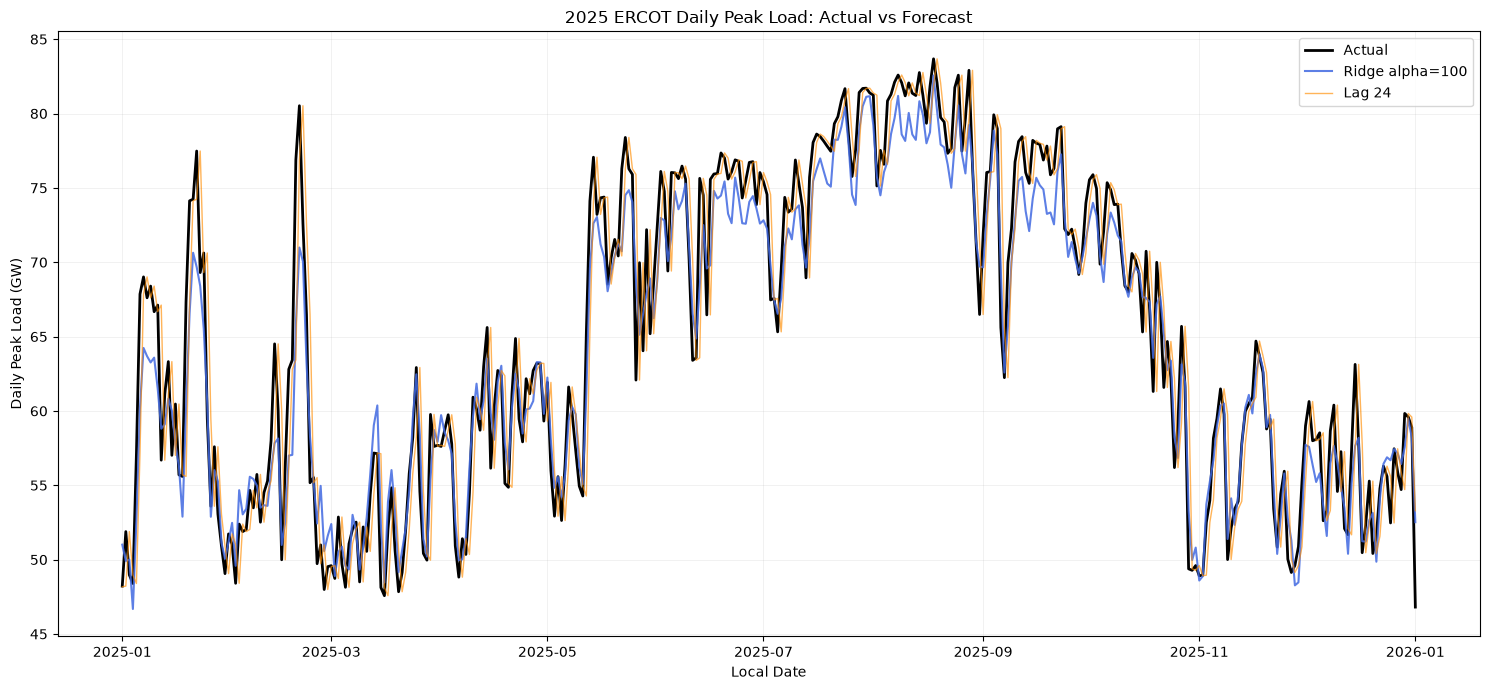

Saved daily peak figure: report/figures/forecasting/test_2025_daily_peak_actual_vs_forecast.png


In [ ]:
# Plot observed and predicted daily peak loads.
final_2025_system_predictions[
    "local_date"
] = (
    final_2025_system_predictions[
        "HourEnding_local"
    ].dt.date
)

final_2025_daily_peak_predictions = (
    final_2025_system_predictions.groupby(
        "local_date",
        as_index=False,
    )
    .agg(
        
        actual_daily_peak_mw=(
            "actual_system_load_mw",
            "max",
        ),

        
        ridge_daily_peak_mw=(
            "ridge_system_prediction_mw",
            "max",
        ),

        
        lag_24_daily_peak_mw=(
            "lag_24_system_prediction_mw",
            "max",
        ),
    )
)

final_2025_daily_peak_predictions[
    "local_date"
] = pd.to_datetime(
    final_2025_daily_peak_predictions[
        "local_date"
    ]
)

report_directory = (
    forecasting_table_directory.parents[1]
)

forecasting_figure_directory = (
    report_directory
    / "figures"
    / "forecasting"
)

forecasting_figure_directory.mkdir(
    parents=True,
    exist_ok=True,
)

forecasting_figure_directory.mkdir(
    parents=True,
    exist_ok=True,
)

print(
    "Forecasting figure directory:",
    display_repo_path(forecasting_figure_directory),
)

daily_peak_figure, daily_peak_axis = plt.subplots(
    figsize=(15, 7)
)

daily_peak_axis.plot(
    final_2025_daily_peak_predictions[
        "local_date"
    ],
    final_2025_daily_peak_predictions[
        "actual_daily_peak_mw"
    ] / 1_000,
    label="Actual",
    color="black",
    linewidth=2,
)

daily_peak_axis.plot(
    final_2025_daily_peak_predictions[
        "local_date"
    ],
    final_2025_daily_peak_predictions[
        "ridge_daily_peak_mw"
    ] / 1_000,
    label="Ridge alpha=100",
    color="royalblue",
    linewidth=1.5,
    alpha=0.85,
)

daily_peak_axis.plot(
    final_2025_daily_peak_predictions[
        "local_date"
    ],
    final_2025_daily_peak_predictions[
        "lag_24_daily_peak_mw"
    ] / 1_000,
    label="Lag 24",
    color="darkorange",
    linewidth=1,
    alpha=0.65,
)

daily_peak_axis.set_title(
    "2025 ERCOT Daily Peak Load: Actual vs Forecast"
)

daily_peak_axis.set_xlabel(
    "Local Date"
)

daily_peak_axis.set_ylabel(
    "Daily Peak Load (GW)"
)

daily_peak_axis.legend()

daily_peak_axis.grid(
    alpha=0.25
)

daily_peak_figure.tight_layout()

daily_peak_figure_path = (
    forecasting_figure_directory
    / "test_2025_daily_peak_actual_vs_forecast.png"
)

daily_peak_figure.savefig(
    daily_peak_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Saved daily peak figure:",
    display_repo_path(daily_peak_figure_path),
)


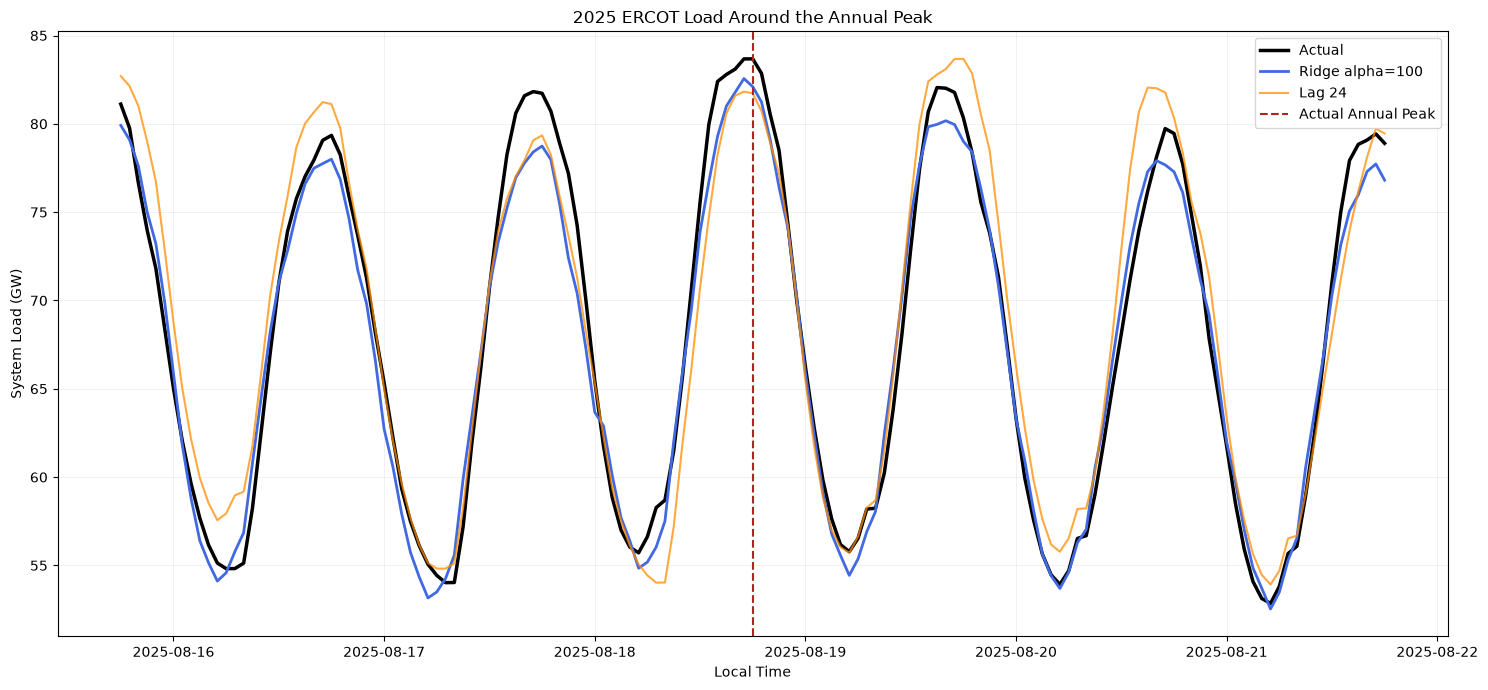

Saved peak-window figure: report/figures/forecasting/test_2025_annual_peak_window.png


In [ ]:
# Plot a local-time window around the observed annual peak.
peak_window_start = (
    actual_peak_time_utc
    - pd.Timedelta(
        hours=72
    )
)

peak_window_end = (
    actual_peak_time_utc
    + pd.Timedelta(
        hours=72
    )
)

final_2025_peak_window = (
    final_2025_system_predictions.loc[
        final_2025_system_predictions[
            "HourEnding_utc"
        ].between(
            peak_window_start,
            peak_window_end,
        )
    ]
    .copy()
)

peak_window_figure, peak_window_axis = plt.subplots(
    figsize=(15, 7)
)

peak_window_axis.plot(
    final_2025_peak_window[
        "HourEnding_local"
    ],
    final_2025_peak_window[
        "actual_system_load_mw"
    ] / 1_000,
    label="Actual",
    color="black",
    linewidth=2.5,
)

peak_window_axis.plot(
    final_2025_peak_window[
        "HourEnding_local"
    ],
    final_2025_peak_window[
        "ridge_system_prediction_mw"
    ] / 1_000,
    label="Ridge alpha=100",
    color="royalblue",
    linewidth=2,
)

peak_window_axis.plot(
    final_2025_peak_window[
        "HourEnding_local"
    ],
    final_2025_peak_window[
        "lag_24_system_prediction_mw"
    ] / 1_000,
    label="Lag 24",
    color="darkorange",
    linewidth=1.5,
    alpha=0.75,
)

peak_window_axis.axvline(
    actual_peak_time_local,
    color="firebrick",
    linestyle="--",
    linewidth=1.5,
    label="Actual Annual Peak",
)

peak_window_axis.set_title(
    "2025 ERCOT Load Around the Annual Peak"
)

peak_window_axis.set_xlabel(
    "Local Time"
)

peak_window_axis.set_ylabel(
    "System Load (GW)"
)

peak_window_axis.legend()

peak_window_axis.grid(
    alpha=0.25
)

peak_window_figure.tight_layout()

peak_window_figure_path = (
    forecasting_figure_directory
    / "test_2025_annual_peak_window.png"
)

peak_window_figure.savefig(
    peak_window_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Saved peak-window figure:",
    display_repo_path(peak_window_figure_path),
)


## 12. Save evaluation artifacts

Export system/regional accuracy summaries, high-load metrics, peak comparisons, hourly predictions, plots, and fitted Ridge pipelines. Downstream peak uncertainty notebooks rely on hourly validation and test predictions.


In [ ]:
# Export the full set of held-out 2025 evaluation results.
final_2025_system_comparison_path = (
    forecasting_table_directory
    / "test_2025_system_model_comparison.csv"
)

final_2025_regional_comparison_path = (
    forecasting_table_directory
    / "test_2025_regional_model_comparison.csv"
)

final_2025_zone_wape_path = (
    forecasting_table_directory
    / "test_2025_zone_wape_comparison.csv"
)

final_2025_monthly_path = (
    forecasting_table_directory
    / "test_2025_monthly_system_comparison.csv"
)

final_2025_seasonal_path = (
    forecasting_table_directory
    / "test_2025_seasonal_system_comparison.csv"
)

final_2025_high_load_path = (
    forecasting_table_directory
    / "test_2025_high_load_comparison.csv"
)

final_2025_peak_path = (
    forecasting_table_directory
    / "test_2025_annual_peak_comparison.csv"
)

final_2025_hourly_predictions_path = (
    forecasting_table_directory
    / "test_2025_system_hourly_predictions.csv"
)

final_2025_system_comparison.to_csv(
    final_2025_system_comparison_path,
    index=False,
)

final_2025_regional_comparison.to_csv(
    final_2025_regional_comparison_path,
    index=False,
)

final_2025_zone_wape_comparison.to_csv(
    final_2025_zone_wape_path,
    index=False,
)

final_2025_monthly_comparison.to_csv(
    final_2025_monthly_path,
    index=False,
)

final_2025_seasonal_comparison.to_csv(
    final_2025_seasonal_path,
    index=False,
)

final_2025_high_load_comparison.to_csv(
    final_2025_high_load_path,
    index=False,
)

final_2025_peak_comparison.to_csv(
    final_2025_peak_path,
    index=False,
)

final_2025_system_predictions.to_csv(
    final_2025_hourly_predictions_path,
    index=False,
)

print(
    "Saved final 2025 system comparison:",
    display_repo_path(final_2025_system_comparison_path),
)

print(
    "Saved final 2025 regional comparison:",
    display_repo_path(final_2025_regional_comparison_path),
)

print(
    "Saved final 2025 high-load comparison:",
    display_repo_path(final_2025_high_load_path),
)

print(
    "Saved final 2025 peak comparison:",
    display_repo_path(final_2025_peak_path),
)

print(
    "Saved final 2025 hourly predictions:",
    display_repo_path(final_2025_hourly_predictions_path),
)


Saved final 2025 system comparison: report/tables/forecasting/test_2025_system_model_comparison.csv
Saved final 2025 regional comparison: report/tables/forecasting/test_2025_regional_model_comparison.csv
Saved final 2025 high-load comparison: report/tables/forecasting/test_2025_high_load_comparison.csv
Saved final 2025 peak comparison: report/tables/forecasting/test_2025_annual_peak_comparison.csv
Saved final 2025 hourly predictions: report/tables/forecasting/test_2025_system_hourly_predictions.csv


> **Saved plot interpretation:** Ridge follows the seasonal and daily load shapes and tracks the rise near the observed annual peak, but tends to underpredict the largest summer loads. Lag-24 often reproduces the previous day's profile and can lag changing peaks by a day. The plots are preserved from the source notebook rather than regenerated in this cleanup.


In [ ]:
# Save curated result tables for the project report.
final_result_tables = {
    
    "test_2025_system_model_comparison.csv":
        final_2025_system_comparison,

    
    "test_2025_regional_model_comparison.csv":
        final_2025_regional_comparison,

    
    "test_2025_zone_wape_comparison.csv":
        final_2025_zone_wape_comparison,

    
    "test_2025_monthly_system_comparison.csv":
        final_2025_monthly_comparison,

    
    "test_2025_seasonal_system_comparison.csv":
        final_2025_seasonal_comparison,

    
    "test_2025_high_load_comparison.csv":
        final_2025_high_load_comparison,

    
    "test_2025_annual_peak_comparison.csv":
        final_2025_peak_comparison,

    
    "test_2025_daily_peak_predictions.csv":
        final_2025_daily_peak_predictions,

    
    "validation_2023_2024_multiyear_system_comparison.csv":
        final_multiyear_validation_comparison,

    
    "validation_2023_2024_model_stability_summary.csv":
        final_multiyear_model_summary,
}

for file_name, result_table in (
    final_result_tables.items()
):
    
    current_output_path = (
        forecasting_table_directory
        / file_name
    )

    
    result_table.to_csv(
        current_output_path,
        index=False,
    )

    
    print(
        f"Saved: {display_repo_path(current_output_path)} "
        f"({len(result_table):,} rows)"
    )


Saved: report/tables/forecasting/test_2025_system_model_comparison.csv (2 rows)
Saved: report/tables/forecasting/test_2025_regional_model_comparison.csv (18 rows)
Saved: report/tables/forecasting/test_2025_zone_wape_comparison.csv (8 rows)
Saved: report/tables/forecasting/test_2025_monthly_system_comparison.csv (24 rows)
Saved: report/tables/forecasting/test_2025_seasonal_system_comparison.csv (8 rows)
Saved: report/tables/forecasting/test_2025_high_load_comparison.csv (6 rows)
Saved: report/tables/forecasting/test_2025_annual_peak_comparison.csv (2 rows)
Saved: report/tables/forecasting/test_2025_daily_peak_predictions.csv (366 rows)
Saved: report/tables/forecasting/validation_2023_2024_multiyear_system_comparison.csv (6 rows)
Saved: report/tables/forecasting/validation_2023_2024_model_stability_summary.csv (3 rows)


In [ ]:
# Save system- and zone-level hourly predictions.
final_2025_system_hourly_output = (
    final_2025_system_predictions[
        [
            "HourEnding_utc",
            "HourEnding_local",
            "local_month",
            "season",
            "actual_system_load_mw",
            "ridge_system_prediction_mw",
            "lag_24_system_prediction_mw",
        ]
    ]
    .copy()
)

final_2025_regional_hourly_output = (
    final_ridge_test_data[
        [
            "HourEnding_utc",
            "zone",
            "load_mw",
            "final_ridge_prediction_mw",
            "lag_24",
            "lag_168",
        ]
    ]
    .copy()
)

final_2025_system_hourly_path = (
    forecasting_table_directory
    / "test_2025_system_hourly_predictions.csv"
)

final_2025_regional_hourly_path = (
    forecasting_table_directory
    / "test_2025_regional_hourly_predictions.csv"
)

final_2025_system_hourly_output.to_csv(
    final_2025_system_hourly_path,
    index=False,
)

final_2025_regional_hourly_output.to_csv(
    final_2025_regional_hourly_path,
    index=False,
)

print(
    "Saved system hourly predictions:",
    display_repo_path(final_2025_system_hourly_path),
)

print(
    "System rows:",
    len(
        final_2025_system_hourly_output
    ),
)

print(
    "Saved regional hourly predictions:",
    display_repo_path(final_2025_regional_hourly_path),
)

print(
    "Regional rows:",
    len(
        final_2025_regional_hourly_output
    ),
)


Saved system hourly predictions: report/tables/forecasting/test_2025_system_hourly_predictions.csv
System rows: 8760
Saved regional hourly predictions: report/tables/forecasting/test_2025_regional_hourly_predictions.csv
Regional rows: 70080


In [ ]:
# Serialize the eight trained Ridge pipelines.
import joblib

final_model_directory = (
    report_directory
    / "models"
    / "forecasting"
)

final_model_directory.mkdir(
    parents=True,
    exist_ok=True,
)

for zone_name, zone_model in (
    final_ridge_models.items()
):
    
    zone_model_path = (
        final_model_directory
        / (
            f"final_ridge_alpha_100_"
            f"{zone_name.lower()}_2019_2024.joblib"
        )
    )

    
    joblib.dump(
        zone_model,
        zone_model_path,
    )

    
    print(
        f"Saved {zone_name} model:",
        display_repo_path(zone_model_path),
    )


Saved COAST model: report/models/forecasting/final_ridge_alpha_100_coast_2019_2024.joblib
Saved EAST model: report/models/forecasting/final_ridge_alpha_100_east_2019_2024.joblib
Saved FWEST model: report/models/forecasting/final_ridge_alpha_100_fwest_2019_2024.joblib
Saved NCENT model: report/models/forecasting/final_ridge_alpha_100_ncent_2019_2024.joblib
Saved NORTH model: report/models/forecasting/final_ridge_alpha_100_north_2019_2024.joblib
Saved SCENT model: report/models/forecasting/final_ridge_alpha_100_scent_2019_2024.joblib
Saved SOUTH model: report/models/forecasting/final_ridge_alpha_100_south_2019_2024.joblib
Saved WEST model: report/models/forecasting/final_ridge_alpha_100_west_2019_2024.joblib


In [ ]:
# Write model features and training-period metadata.
final_model_metadata = pd.DataFrame(
    {
        
        "feature_name": (
            ridge_feature_columns
        ),

        
        "model": (
            "Ridge alpha=100"
        ),

        
        "training_period": (
            "2019-2024"
        ),

        
        "test_year": 2025,
    }
)

final_model_metadata_path = (
    final_model_directory
    / "final_ridge_alpha_100_metadata.csv"
)

final_model_metadata.to_csv(
    final_model_metadata_path,
    index=False,
)


print(
    "Saved model metadata:",
    display_repo_path(final_model_metadata_path),
)


Saved model metadata: report/models/forecasting/final_ridge_alpha_100_metadata.csv


In [ ]:
# Verify that required forecasting artifacts were written.
final_required_files = [
    
    daily_peak_figure_path,
    peak_window_figure_path,

    
    final_2025_system_hourly_path,
    final_2025_regional_hourly_path,

    
    forecasting_table_directory
    / "test_2025_system_model_comparison.csv",

    forecasting_table_directory
    / "test_2025_regional_model_comparison.csv",

    forecasting_table_directory
    / "test_2025_high_load_comparison.csv",

    forecasting_table_directory
    / "test_2025_annual_peak_comparison.csv",

    forecasting_table_directory
    / "test_2025_monthly_system_comparison.csv",

    forecasting_table_directory
    / "test_2025_seasonal_system_comparison.csv",

    
    final_model_metadata_path,
]

final_output_check = pd.DataFrame(
    {
        
        "path": [
            display_repo_path(file_path)
            for file_path in final_required_files
        ],

        
        "exists": [
            file_path.exists()
            for file_path in final_required_files
        ],

        
        "size_bytes": [
            (
                file_path.stat().st_size
                if file_path.exists()
                else 0
            )
            for file_path in final_required_files
        ],
    }
)

display(
    final_output_check
)

if not final_output_check[
    "exists"
].all():
    raise FileNotFoundError(
        "Some required forecasting output files were not saved."
    )


print(
    "All final forecasting outputs were saved successfully."
)


,path,exists,size_bytes
0,repor...,True,992406
1,repor...,True,665751
2,repor...,True,931062
3,repor...,True,6079342
4,repor...,True,267
5,repor...,True,2013
6,repor...,True,1077
7,repor...,True,891
8,repor...,True,2538
9,repor...,True,966


All final forecasting outputs were saved successfully.


## 13. Export 2023–2024 hourly rolling-validation predictions

This final stage restores regional and system hourly predictions for the earlier rolling-validation years. These data are needed to estimate historical residual behavior in the subsequent peak-uncertainty stage. It requires variables calculated earlier in this notebook; it is not a standalone script.


In [ ]:
# Export and verify the regional/system hourly 2023–2024 validation predictions.
# ============================================================

# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------

# ------------------------------------------------------------
required_objects = [
    "rolling_2023_predictions",
    "ridge_validation_data",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Missing prior validation objects in this notebook session: "
        + ", ".join(missing_objects)
        + ". Run this notebook from the beginning before this cell."
    )

# ------------------------------------------------------------

# ------------------------------------------------------------
if "forecasting_table_directory" in globals():
    FORECAST_OUTPUT_DIR = Path(
        forecasting_table_directory
    )
else:
    FORECAST_OUTPUT_DIR = (
        project_root
        / "report"
        / "tables"
        / "forecasting"
    )

FORECAST_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# ------------------------------------------------------------


# ------------------------------------------------------------
regional_2023_hourly = (
    rolling_2023_predictions[
        [
            "HourEnding_utc",
            "zone",
            "load_mw",
            "lag_24",
            "ridge_prediction_mw",
        ]
    ]
    .copy()
)

regional_2023_hourly.insert(
    0,
    "validation_year",
    2023,
)

# ------------------------------------------------------------


# ------------------------------------------------------------
regional_2024_hourly = (
    ridge_validation_data[
        [
            "HourEnding_utc",
            "zone",
            "load_mw",
            "lag_24",
            "best_ridge_prediction_mw",
        ]
    ]
    .rename(
        columns={
            "best_ridge_prediction_mw":
                "ridge_prediction_mw",
        }
    )
    .copy()
)

regional_2024_hourly.insert(
    0,
    "validation_year",
    2024,
)

# ------------------------------------------------------------

# ------------------------------------------------------------
historical_regional_hourly = pd.concat(
    [
        regional_2023_hourly,
        regional_2024_hourly,
    ],
    ignore_index=True,
)

historical_regional_hourly["HourEnding_utc"] = (
    pd.to_datetime(
        historical_regional_hourly[
            "HourEnding_utc"
        ].astype(str).tolist(),
        format="mixed",
        utc=True,
        errors="raise",
    )
)

historical_regional_hourly["zone"] = (
    historical_regional_hourly["zone"]
    .astype(str)
    .str.strip()
    .str.upper()
)

historical_regional_hourly = (
    historical_regional_hourly
    .sort_values(
        [
            "HourEnding_utc",
            "zone",
        ]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------

# ------------------------------------------------------------
historical_system_hourly = (
    historical_regional_hourly
    .groupby(
        [
            "validation_year",
            "HourEnding_utc",
        ],
        as_index=False,
    )
    .agg(
        actual_system_load_mw=(
            "load_mw",
            "sum",
        ),
        ridge_system_prediction_mw=(
            "ridge_prediction_mw",
            "sum",
        ),
        lag_24_system_prediction_mw=(
            "lag_24",
            "sum",
        ),
        zone_count=(
            "zone",
            "nunique",
        ),
    )
)

# ------------------------------------------------------------

# ------------------------------------------------------------
duplicate_regional_keys = int(
    historical_regional_hourly.duplicated(
        [
            "HourEnding_utc",
            "zone",
        ]
    ).sum()
)

missing_regional_values = int(
    historical_regional_hourly[
        [
            "load_mw",
            "ridge_prediction_mw",
            "lag_24",
        ]
    ].isna().sum().sum()
)

incomplete_system_hours = int(
    historical_system_hourly[
        "zone_count"
    ].ne(8).sum()
)

year_summary = (
    historical_regional_hourly
    .groupby("validation_year")
    .agg(
        regional_rows=("zone", "size"),
        system_hours=(
            "HourEnding_utc",
            "nunique",
        ),
        zone_count=("zone", "nunique"),
        first_utc=("HourEnding_utc", "min"),
        last_utc=("HourEnding_utc", "max"),
    )
    .reset_index()
)

quality_summary = pd.Series(
    {
        "regional_total_rows":
            len(historical_regional_hourly),
        "system_total_hours":
            len(historical_system_hourly),
        "duplicate_timestamp_zone_keys":
            duplicate_regional_keys,
        "missing_required_regional_values":
            missing_regional_values,
        "incomplete_system_hours":
            incomplete_system_hours,
    },
    name="value",
)

print("Historical validation summary by year:")
display(year_summary)

print("\nHistorical validation quality summary:")
print(quality_summary.to_string())

if duplicate_regional_keys != 0:
    raise ValueError(
        "Duplicate timestamp-zone keys in historical regional validation data."
    )

if missing_regional_values != 0:
    raise ValueError(
        "Missing required values in historical regional validation data."
    )

if incomplete_system_hours != 0:
    raise ValueError(
        "Some system hours have fewer than eight zones; residuals cannot be aggregated safely."
    )

# ------------------------------------------------------------

# ------------------------------------------------------------
REGIONAL_HISTORY_PATH = (
    FORECAST_OUTPUT_DIR
    / "validation_2023_2024_regional_hourly_predictions.csv"
)

SYSTEM_HISTORY_PATH = (
    FORECAST_OUTPUT_DIR
    / "validation_2023_2024_system_hourly_predictions.csv"
)

historical_regional_hourly.to_csv(
    REGIONAL_HISTORY_PATH,
    index=False,
)

historical_system_hourly.to_csv(
    SYSTEM_HISTORY_PATH,
    index=False,
)

# ------------------------------------------------------------

# ------------------------------------------------------------
regional_saved_check = pd.read_csv(
    REGIONAL_HISTORY_PATH,
)

system_saved_check = pd.read_csv(
    SYSTEM_HISTORY_PATH,
)

save_check = pd.DataFrame(
    [
        {
            "file": REGIONAL_HISTORY_PATH.name,
            "exists": REGIONAL_HISTORY_PATH.exists(),
            "rows_written":
                len(historical_regional_hourly),
            "rows_read_back":
                len(regional_saved_check),
            "size_bytes":
                REGIONAL_HISTORY_PATH.stat().st_size,
        },
        {
            "file": SYSTEM_HISTORY_PATH.name,
            "exists": SYSTEM_HISTORY_PATH.exists(),
            "rows_written":
                len(historical_system_hourly),
            "rows_read_back":
                len(system_saved_check),
            "size_bytes":
                SYSTEM_HISTORY_PATH.stat().st_size,
        },
    ]
)

save_check["row_count_matches"] = (
    save_check["rows_written"]
    == save_check["rows_read_back"]
)

print("\nSaved-file readback verification:")
display(save_check)

if not (
    save_check["exists"].all()
    and save_check["row_count_matches"].all()
):
    raise RuntimeError(
        "Historical hourly-validation output failed readback verification."
    )

print(
    "\nHistorical hourly validation predictions "
    "were saved successfully."
)


Historical validation summary by year:


,validation_year,regional_rows,system_hours,zone_count,first_utc,last_utc
0,2023,70080,8760,8,2023-01-01 07:00:00+00:00,2024-01-01 06:00:00+00:00
1,2024,70272,8784,8,2024-01-01 07:00:00+00:00,2025-01-01 06:00:00+00:00



Historical validation quality summary:
regional_total_rows                 140352
system_total_hours                   17544
duplicate_timestamp_zone_keys            0
missing_required_regional_values         0
incomplete_system_hours                  0

Saved-file readback verification:


,file,exists,rows_written,rows_read_back,size_bytes,row_count_matches
0,validation_2023_2024_regional_hourly_predictio...,True,140352,140352,11156651,True
1,validation_2023_2024_system_hourly_predictions...,True,17544,17544,1379007,True



Historical hourly validation predictions were saved successfully.


## 14. Final forecasting conclusions

- **Model selection:** Ridge with `alpha=100` was selected as the final hourly load model after chronological validation on 2023 and 2024.
- **2025 system evaluation:** Ridge reached a saved WAPE of **3.258%**, versus **4.519%** for the lag-24 baseline. The improvement is measured with historical lagged loads and observed contemporaneous weather.
- **2025 zone-level evaluation:** Ridge outperformed lag-24 across all eight weather zones; pooled regional WAPE was approximately **4.426%** versus **6.022%**.
- **Peak timing versus peak magnitude:** The model's predicted annual maximum was about **1.12 GW** below the observed annual peak, despite close peak timing (about one hour). Do not conflate a forecast's own annual maximum with its prediction at the hour of the observed maximum.
- **Highest-load hours:** Ridge underpredicted the load in the observed top 1% load group. Strong overall hourly WAPE therefore does not establish adequate unadjusted planning peaks.
- **Next steps:** Use saved historical out-of-sample residuals to investigate peak bias and uncertainty scenarios (P50, P90, P95) in the subsequent notebook. These scenarios are not validated probabilistic coverage claims.

*The displayed numerical results and plots are preserved from the supplied notebook; no end-to-end model rerun was performed during the English/privacy cleanup.*
